# Evaluate primer-tag tracking and taxonomy

This notebook evaluates one selected sequencing barcode at the original ONT-read level. Set `SELECTED_BARCODE` in the environment for batch execution, or use the default `barcode01` interactively. The input is long-format, so adapter-split reads can occupy multiple rows. adapter-split reads originate from fastplong finding barcodes+adaptors in the middle of the read. Read-count analyses deduplicate `raw_ont_read_id` to prevent those fragments from inflating counts.

Workflow: load the reduced table; choose an effective taxid and record its source; summarize forward and reverse best hits; measure taxid diversity; compare diversity with read depth; and list the ten most frequent taxa per forward primer.

In [1]:
from pathlib import Path
import os
import re

import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
import pandas as pd

# Resolve paths whether Jupyter starts in the project root or code/ directory.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'code' else Path.cwd()

# Set SELECTED_BARCODE in the environment for batch execution.
# Example: SELECTED_BARCODE=barcode02 jupyter nbconvert --execute ...
SELECTED_BARCODE = os.environ.get('SELECTED_BARCODE', 'barcode01')
INPUT_FILE = PROJECT_ROOT / f'data/mergedseq5/{SELECTED_BARCODE}/{SELECTED_BARCODE}_read_primer_group_taxid_reduced.tsv'
INSECTA_INPUT_FILE = PROJECT_ROOT / f'data/mergedseq5/{SELECTED_BARCODE}/{SELECTED_BARCODE}_insecta_read_primer_group_taxid_reduced.tsv'

# the following should remain stable unless the files are re-generated (particularly read maps
# after re running amplicon_sorter and kraken2)
FIGURES_DIR = INPUT_FILE.parent / 'figures'
MFT_PRIMERS_FASTA = PROJECT_ROOT / 'data/saproxdna_primertags_seq5_2026_1.fasta'
PCR_PRIMERS_FASTA = PROJECT_ROOT / 'data/PCRsaproxdna_primertags_seq5_2026_1.fasta'
POOL_MAP_FILE = PROJECT_ROOT / 'saproxDNA/species_info_seq5/seq5_pcr_to_pools.tsv'
PCR_TO_SAMPLE_FILE = PROJECT_ROOT / 'saproxDNA/species_info_seq5/PCR_to_species_20260602.txt'

# update if taxonomists send more data on morphologically identified specimens
SAMPLE_TO_SPECIES_FILE = PROJECT_ROOT / 'saproxDNA/species_info_seq5/saproxdna_tospecies_20260630_v1.tsv'

# only modify the paths below if your database sits somewhere else or if you use a different database
# for kraken2
KRAKEN_DB = Path('/mnt/d/kraken2DB/k2_core_nt_2025')
NAMES_DMP = KRAKEN_DB / 'names.dmp'
NODES_DMP = KRAKEN_DB / 'nodes.dmp'

# keep this false if you don't want to count reads unclassified for e.g. reads per forward primer detected
INCLUDE_UNCLASSIFIED_TAXID = False  # Kraken taxid 0 means unclassified
FIGURES_DIR.mkdir(exist_ok=True)

plt.style.use('default')

def make_discrete_colors(categories, cmap_name='viridis'):
    # sample equidistant colors from a perceptually uniform matplotlib colormap.
    categories = list(dict.fromkeys(categories))
    cmap = plt.colormaps[cmap_name].resampled(max(len(categories), 1))
    return {category: cmap(index) for index, category in enumerate(categories)}
    
# load and parse only the columns needed, the input file is pretty large.
ANALYSIS_COLUMNS = [
    'raw_ont_read_id',
    'forward_patternName',
    'reverse_patternName',
    'group_consensus_kraken_taxid',
    'individual_read_kraken_taxid']


## Load the complete and Insecta reduced tracking tables

Both files contain only the five columns required by this notebook. `tracking` contains every barcode read, while `insecta_tracking` contains only rows connected to an Insecta Kraken consensus or individual-read assignment. Their complete annotated tables remain gzip-compressed.

In [2]:
TRACKING_DTYPES = {
    'raw_ont_read_id': 'string',
    'forward_patternName': 'string',
    'reverse_patternName': 'string',
    'group_consensus_kraken_taxid': 'Int64',
    'individual_read_kraken_taxid': 'Int64',
}

def load_reduced_tracking(path):
    return pd.read_csv(
        path, sep='\t', usecols=ANALYSIS_COLUMNS, dtype=TRACKING_DTYPES)

tracking = load_reduced_tracking(INPUT_FILE)
insecta_tracking = load_reduced_tracking(INSECTA_INPUT_FILE)

print(f'Loaded all reads: {len(tracking):,} rows and '
    f'{tracking.raw_ont_read_id.nunique():,} raw reads')
print(f'Loaded Insecta reads: {len(insecta_tracking):,} rows and '
    f'{insecta_tracking.raw_ont_read_id.nunique():,} raw reads')

Loaded all reads: 493,553 rows and 492,977 raw reads
Loaded Insecta reads: 311,880 rows and 311,475 raw reads


## Data lineage of tables created in this notebook

The two read-level inputs have different scopes:

- `tracking` contains all raw reads for the selected sequencing barcode.
- `insecta_tracking` is the Insecta subset traced back to those raw reads through amplicon_sorter groups and individual-read IDs.

The following table records which input contributes to each derived table. “Tracking with Insecta membership” means the rows originate from `tracking`, while membership in `insecta_tracking` supplies the Insecta count.

| Derived table | Read-data source | Additional information or purpose |
|---|---|---|
| `read_status` | Both `tracking` and `insecta_tracking` | Concatenated read-level primer-detection and classification status, with a `dataset` column. |
| `primer_detection_long` | Both inputs through `read_status` | Long-format counts and percentages by dataset, primer detection and classification. |
| `primer_detection_summary` | Both inputs through `primer_detection_long` | Wide comparison of tracking and Insecta counts and percentages. |
| `primer_reads` | `tracking` with Insecta membership | Deduplicated raw-read/primer associations; this variable is reused for primer-pair and forward-primer summaries. |
| `reads_per_primer_pair` | `tracking` with Insecta membership | Total and Insecta raw-read counts for each forward/reverse primer pair. |
| `reads_per_forward` | `tracking` with Insecta membership | Total and Insecta raw-read counts for each forward primer. |
| `reverse_reads` | `tracking` with Insecta membership | Deduplicated reverse-primer/raw-read associations. |
| `reads_per_reverse_tag` | `tracking` with Insecta membership | Total, Insecta and calculated non-Insecta counts for each reverse primer. |
| `tag_taxid_pre` | `tracking` | Classified forward-primer/taxid rows used for all-read taxid diversity. |
| `unique_taxids_per_forward_all` | `tracking` | Unique classified taxids per forward primer across all reads. |
| `tag_taxid` | `insecta_tracking` | Classified forward-primer/taxid rows used by subsequent Insecta taxonomy tables. |
| `unique_taxids_per_forward_tag` | Primarily `insecta_tracking` | Insecta read count and unique Insecta taxids; `unique_taxid_noninsecta` additionally subtracts these from the all-read taxid counts. |
| `taxonomy_reads` | `insecta_tracking` | Classified Insecta rows whose taxids are resolved against NCBI taxonomy. |
| `tag_taxid_read_counts` | `insecta_tracking` through `tag_taxid` | Distinct Insecta raw-read counts for each forward-primer/taxid association. |
| `top10_long`, `top10_names`, `top10_counts` | `insecta_tracking` | Ranked long and pivoted forms of the ten most frequent Insecta taxids per forward primer. |
| `top10_taxa_per_forward_tag` | `insecta_tracking` plus metadata | Starts from the Insecta top-ten table, then receives PCR/sample/species metadata and NCBI lineage annotations. |
| `pool_map`, `pcr_to_sample`, `sample_to_species` | External metadata files | Barcode-to-PCR, PCR-to-sample and sxdcode-to-target-species lookup tables; these are not read data. |
| `selected_samples`, `species_lookup`, `primer_sample_lookup` | External metadata | Intermediate lookup tables used to annotate `top10_taxa_per_forward_tag`. |
| `top1_lineage` | Insecta top-ranked taxids plus NCBI taxonomy | Genus and family of each primer's most frequent Insecta taxid. |
| `target_detection_reads`, `target_detection_summary` | `insecta_tracking` through `tag_taxid` | Insecta reads whose assigned taxid genus matches the expected target genus. |
| `unsorted_reads`, `unsorted` | `insecta_tracking` | Classified Insecta reads without a detected forward primer, summarized by taxid and matched to target metadata by genus. |
| `stacked_taxa`, `unclassified_per_forward` | `insecta_tracking` | Data used for the stacked top-ten taxid plot; `stacked_taxa` comes through `top10_long`. |
| `target_species_detection_table` | `insecta_tracking` plus target metadata and NCBI taxonomy | One row per target species, matching taxid and forward-primer status; includes expected primers from PCR design metadata, seqkit-detected primers, primer agreement flags, detected-taxid name/genus, read counts and a flag for taxids found with at least 50% of forward primers. |
| `widespread_taxids` | `insecta_tracking` plus PCR design metadata | Taxids detected with at least 50% of observed forward primers, their scientific name/genus, detected/missing primer lists, expected primers for detected forward primers, primer agreement flags, supporting read counts and evidence among reads without a forward primer. |
| `target_species_taxids_below_50pct` | Filtered `target_species_detection_table` | Target-species rows with a detected taxid that is not found with at least 50% of observed forward primers; retains both detected- and undetected-forward-primer rows. |
| `expected_species_not_detected` | Filtered target metadata plus `target_species_detection_table` | Expected target species whose genus was not detected in any classified Insecta read, with expected sxdcode and expected primer context from PCR design metadata. |

Variables such as `plot_data`, `temp`, `bottom`, `rank_colors` and legend objects are temporary plotting or diagnostic objects rather than independent biological tables.

The exported tables therefore have these sources:

- `*_top10_taxa_per_forward_tag.tsv`: Insecta read/taxid data plus sample, target-species and NCBI lineage metadata.
- `*_unsorted_taxa.tsv`: Insecta reads without a forward-primer detection plus target-species metadata.
- `*_primer_detection_classification_summary.tsv`: comparison of `tracking` and `insecta_tracking`.

- `*_target_species_detection.tsv`: target-genus-matching Insecta detections expanded by target species, primer status and taxid.
- `*_taxids_across_50pct_forward_primers.tsv`: Insecta taxids observed with at least 50% of forward primers, including no-forward-primer evidence.
- `*_target_species_taxids_below_50pct_forward_primers.tsv`: target-species detections whose taxid does not meet the 50% forward-primer threshold.
- `*_expected_species_not_detected.tsv`: expected target species with no matching detected taxid genus in the Insecta tracking table.

## Replace MFT primer names with PCR barcode names

The tracking table initially uses names such as `forward_tagged_primer_24` (from MFT's listing; sequences are the same only the name is different). The cross-match code identifies the equivalent primer name used in PCR spreadsheets by exact primer-sequence identity. Here we rebuild its `mft_to_pcr_names` dictionary from the two FASTA files and replace both primer-name columns before any summaries are calculated. The code stops if an observed primer lacks a mapping.

In [3]:
# creates a dictionary from the fasta files containing the primers
# MFT primer file contains forward and reverse primers
# PCR primer file should contain these too
# need to update the files as we use more different primers
def read_fasta_as_dict(path):
    records = {}
    record_id = None
    sequence_parts = []
    with open(path, encoding='utf-8') as handle:
        for line in handle:
            line = line.strip()
            if not line:
                continue
            if line.startswith('>'):
                if record_id is not None:
                    records[record_id] = ''.join(sequence_parts).upper()
                record_id = line.removeprefix('>').split()[0]
                sequence_parts = []
            else:
                sequence_parts.append(line)
    if record_id is not None:
        records[record_id] = ''.join(sequence_parts).upper()
    return records

mft_primers = read_fasta_as_dict(MFT_PRIMERS_FASTA)
pcr_primers = read_fasta_as_dict(PCR_PRIMERS_FASTA)
# invert for comparison
pcr_by_value = {sequence: name for name, sequence in pcr_primers.items()}
mft_to_pcr_names = {
    mft_name: pcr_by_value[sequence]
    for mft_name, sequence in mft_primers.items()
    if sequence in pcr_by_value}

for table_name, table in [('all reads', tracking), ('Insecta', insecta_tracking)]:
    for column in ['forward_patternName', 'reverse_patternName']:
        observed_names = set(table[column].dropna().unique())
        missing_names = observed_names.difference(mft_to_pcr_names)
        if missing_names:
            raise ValueError(f'Primer names missing from mft_to_pcr_names in {table_name}: '
                f'{sorted(missing_names)}'            )
        table[column] = table[column].map(mft_to_pcr_names).astype('string')

print(f'Mapped {len(mft_to_pcr_names):,} MFT primer names to PCR names')
# just a show of the primer names changed in the dataframe, to make sure name conversion worked
display(tracking[['forward_patternName', 'reverse_patternName']].head())
display(insecta_tracking[['forward_patternName', 'reverse_patternName']].head())


Mapped 99 MFT primer names to PCR names


,forward_patternName,reverse_patternName
0,<NA>,<NA>
1,bc1043,<NA>
2,<NA>,bc1107rc
3,<NA>,bc1107rc
4,bc1055,<NA>


,forward_patternName,reverse_patternName
0,bc1004,bc1107rc
1,bc1055,<NA>
2,<NA>,bc1107rc
3,<NA>,<NA>
4,<NA>,bc1107rc


## Define the taxid used for each processed read

Grouped reads use the propagated `group_consensus_kraken_taxid`; ungrouped unique sequences use their direct `individual_read_kraken_taxid`. `combine_first` chooses the group value when present and otherwise the individual value. Taxid 0 remains a real Kraken *unclassified* result, and `taxid_source` preserves provenance.

In [4]:
taxid_columns = ['group_consensus_kraken_taxid','individual_read_kraken_taxid']

for column in taxid_columns:
    tracking[column] = pd.to_numeric(tracking[column], errors='coerce').astype('Int64')
    insecta_tracking[column] = pd.to_numeric(insecta_tracking[column], errors='coerce').astype('Int64')

tracking['taxid'] = tracking['group_consensus_kraken_taxid'].combine_first(tracking['individual_read_kraken_taxid'])
insecta_tracking['taxid'] = insecta_tracking['group_consensus_kraken_taxid'].combine_first(insecta_tracking['individual_read_kraken_taxid'])

tracking['taxid_source'] = 'none'
tracking.loc[tracking['individual_read_kraken_taxid'].notna(), 'taxid_source'] = 'individual_read'
tracking.loc[tracking['group_consensus_kraken_taxid'].notna(), 'taxid_source'] = 'group_consensus'

insecta_tracking['taxid_source'] = 'none'
insecta_tracking.loc[insecta_tracking['individual_read_kraken_taxid'].notna(), 'taxid_source'] = 'individual_read'
insecta_tracking.loc[insecta_tracking['group_consensus_kraken_taxid'].notna(), 'taxid_source'] = 'group_consensus'

# for numeric sorting of primers, extracts the number at the end of the primer name
# Extract the numeric part from bc1001 and bc1100rc for numeric sorting.
tracking['forward_tag_number'] = pd.to_numeric(tracking['forward_patternName'].str.extract(r'^bc(\d+)', expand=False),
    errors='coerce')
tracking['reverse_tag_number'] = pd.to_numeric(tracking['reverse_patternName'].str.extract(r'^bc(\d+)', expand=False),
    errors='coerce')

insecta_tracking['forward_tag_number'] = pd.to_numeric(insecta_tracking['forward_patternName'].str.extract(r'^bc(\d+)', expand=False),
    errors='coerce')
insecta_tracking['reverse_tag_number'] = pd.to_numeric(insecta_tracking['reverse_patternName'].str.extract(r'^bc(\d+)', expand=False),
    errors='coerce')

display(tracking[['taxid_source', 'taxid']].value_counts(dropna=False))
display(insecta_tracking[['taxid_source', 'taxid']].value_counts(dropna=False))

taxid_source     taxid  
none             <NA>       94686
individual_read  0          46154
                 3077936    24886
                 2882605    17087
                 43754      13824
                            ...  
                 1812123        1
                 1724510        1
                 2707299        1
                 1474103        1
                 1692833        1
Name: count, Length: 7147, dtype: int64

taxid_source     taxid  
individual_read  2882605    17087
                 43754      13824
                 7218       12673
                 500306     11862
                 3095590    10343
                            ...  
                 1773162        1
                 1773009        1
                 1724510        1
                 1474103        1
                 1692833        1
Name: count, Length: 5686, dtype: int64

## Forward-primer detection and classification

This comparison counts each original ONT read once, even when fastplong produced multiple rows from one read. A forward primer is detected when any row for that raw read has `forward_patternName`. A read is classified when any row has an effective taxid other than Kraken taxid 0. Percentages are calculated within each primer-detected or primer-not-detected category, separately for `tracking` and `insecta_tracking`.

,forward_primer_detection,classification,tracking_read_count,tracking_percentage,insecta_tracking_read_count,insecta_tracking_percentage
0,detected,classified,221729,75.85,197659,100.0
1,detected,unclassified,70610,24.15,0,0.0
2,not_detected,classified,127479,63.54,113816,100.0
3,not_detected,unclassified,73159,36.46,0,0.0


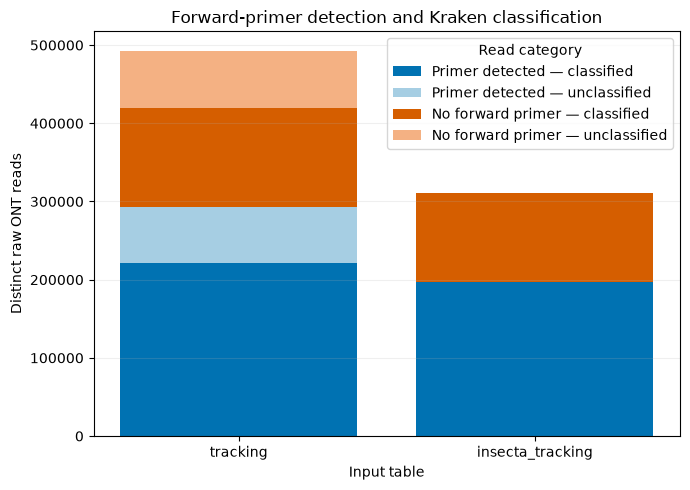

In [5]:
# flexible wrappers (eq, ne, le, lt, ge, gt) equivalent to ==, !=, <=, <, >=, > 
def raw_read_status(data, dataset_name):
    # return booleans for each condition assigned
    read_status = (data.assign(forward_primer_detected = data['forward_patternName'].notna(),
        classified = data['taxid'].notna() & data['taxid'].ne(0))
        .groupby('raw_ont_read_id', as_index = False)
        .agg(forward_primer_detected = ('forward_primer_detected', 'any'),
            classified = ('classified', 'any')))
    read_status['dataset'] = dataset_name
    return read_status

read_status = pd.concat([raw_read_status(tracking, 'tracking'),
    raw_read_status(insecta_tracking, 'insecta_tracking')], ignore_index=True)

# translates the booleans
read_status['forward_primer_detection'] = read_status['forward_primer_detected'].map({True: 'detected', False: 'not_detected'})
read_status['classification'] = read_status['classified'].map({True: 'classified', False: 'unclassified'})

# indices across the three categories we want to explore: dataset, primer detection, taxid assignment
category_index = pd.MultiIndex.from_product([
    ['tracking', 'insecta_tracking'],
    ['detected', 'not_detected'],
    ['classified', 'unclassified']],
    names=['dataset', 'forward_primer_detection', 'classification'])

primer_detection_long = (read_status.groupby(['dataset', 'forward_primer_detection', 'classification']).size()
    .reindex(category_index, fill_value = 0)
    .rename('read_count').reset_index())

primer_detection_long['percentage'] = (100 * primer_detection_long['read_count']/ primer_detection_long
    .groupby(['dataset', 'forward_primer_detection'])['read_count'].transform('sum')).fillna(0).round(2)

primer_detection_summary = (primer_detection_long.pivot(
    index=['forward_primer_detection', 'classification'],
    columns='dataset', values=['read_count', 'percentage']).reset_index())

# remanes the columns of the pivot table
primer_detection_summary.columns = ['forward_primer_detection', 'classification',
    'insecta_tracking_read_count', 'tracking_read_count',
    'insecta_tracking_percentage', 'tracking_percentage']
# re-orders the columns based on personal taste
primer_detection_summary = primer_detection_summary[[
    'forward_primer_detection', 'classification',
    'tracking_read_count', 'tracking_percentage',
    'insecta_tracking_read_count', 'insecta_tracking_percentage']]

for column in ['tracking_read_count', 'insecta_tracking_read_count']:
    primer_detection_summary[column] = primer_detection_summary[column].astype(int)
display(primer_detection_summary)

# plotting the data
# primer_status, classification, color, label
stack_categories = [
    ('detected', 'classified', '#0072B2', 'Primer detected — classified'),
    ('detected', 'unclassified', '#A6CEE3', 'Primer detected — unclassified'),
    ('not_detected', 'classified', '#D55E00', 'No forward primer — classified'),
    ('not_detected', 'unclassified', '#F4B183', 'No forward primer — unclassified')]
dataset_order = ['tracking', 'insecta_tracking']
bottom = pd.Series(0, index = dataset_order, dtype = 'int64')

fig, ax = plt.subplots(figsize = (7, 5))
for primer_status, classification, color, label in stack_categories:
    heights = (primer_detection_long[
        (primer_detection_long['forward_primer_detection'] == primer_status)
        & (primer_detection_long['classification'] == classification)]
        .set_index('dataset')['read_count'].reindex(dataset_order, fill_value = 0))
    # print('heights\n', heights)
    # print('bottom\n', bottom)
    ax.bar(dataset_order, heights, bottom = bottom, color = color, label = label)
    bottom = bottom + heights
ax.set(title='Forward-primer detection and Kraken classification',
    xlabel='Input table', ylabel='Distinct raw ONT reads')
ax.grid(axis='y', alpha=0.2)
ax.grid(axis='x', visible=False)
ax.legend(title='Read category')
plt.tight_layout()
fig.savefig(FIGURES_DIR / f'{SELECTED_BARCODE}_primer_detection_classification.png',
    dpi=250, bbox_inches='tight')
plt.show()


## Reads per forward primer tag

A split raw read (split by fastplong due to internal adapters) may occupy two table rows. Deduplicating `(forward tag, raw read ID)` pairs makes `read_count` the number of distinct original ONT reads per best forward hit.

Building a table directly from tracking, marking which raw reads occur in insecta_tracking

In [6]:
insecta_raw_read_ids = set(insecta_tracking['raw_ont_read_id'].dropna())

primer_reads = (tracking[['raw_ont_read_id','forward_patternName','reverse_patternName']]
    .dropna(subset=['forward_patternName'])
    .drop_duplicates()
    .copy())

primer_reads['is_insecta'] = primer_reads['raw_ont_read_id'].isin(insecta_raw_read_ids)

reads_per_primer_pair = (primer_reads.groupby(['forward_patternName', 'reverse_patternName'],dropna=False, as_index=False)
    .agg(read_count=('raw_ont_read_id', 'nunique'), read_count_insecta=('is_insecta', 'sum')))

reads_per_primer_pair['read_count_insecta'] = (reads_per_primer_pair['read_count_insecta'].astype(int))
display(reads_per_primer_pair)

,forward_patternName,reverse_patternName,read_count,read_count_insecta
0,bc1001,bc1107rc,1298,496
1,bc1001,bc1122rc,6,4
2,bc1001,<NA>,925,319
3,bc1002,bc1107rc,52,7
4,bc1002,bc1122rc,3,3
...,...,...,...,...
281,bc1095,bc1122rc,8,5
282,bc1095,<NA>,472,94
283,bc1096,bc1107rc,21,15
284,bc1096,bc1122rc,51,9


In [7]:
primer_reads = (tracking[['raw_ont_read_id','forward_patternName']]
    .dropna(subset=['forward_patternName'])
    .drop_duplicates()
    .copy())

primer_reads['is_insecta'] = primer_reads['raw_ont_read_id'].isin(insecta_raw_read_ids)

reads_per_forward = (primer_reads.groupby(['forward_patternName'], dropna=False, as_index=False)
    .agg(read_count=('raw_ont_read_id', 'nunique'), read_count_insecta=('is_insecta', 'sum')))

reads_per_forward['read_count_insecta'] = (reads_per_forward['read_count_insecta'].astype(int))

# with pd.option_context('display.max_rows', None):
#     display(reads_per_forward)
display(reads_per_forward.sort_values(by = 'read_count_insecta', ascending = False))

,forward_patternName,read_count,read_count_insecta
65,bc1066,11532,10274
82,bc1083,10019,8928
61,bc1062,9872,8859
42,bc1043,8333,7506
46,bc1047,8066,7428
...,...,...,...
71,bc1072,41,26
1,bc1002,121,25
83,bc1084,37,24
10,bc1011,40,17


Because read_count_insecta is already included in read_count, calculate the non-Insecta remainder before stacking. Otherwise Insecta reads would be counted twice.

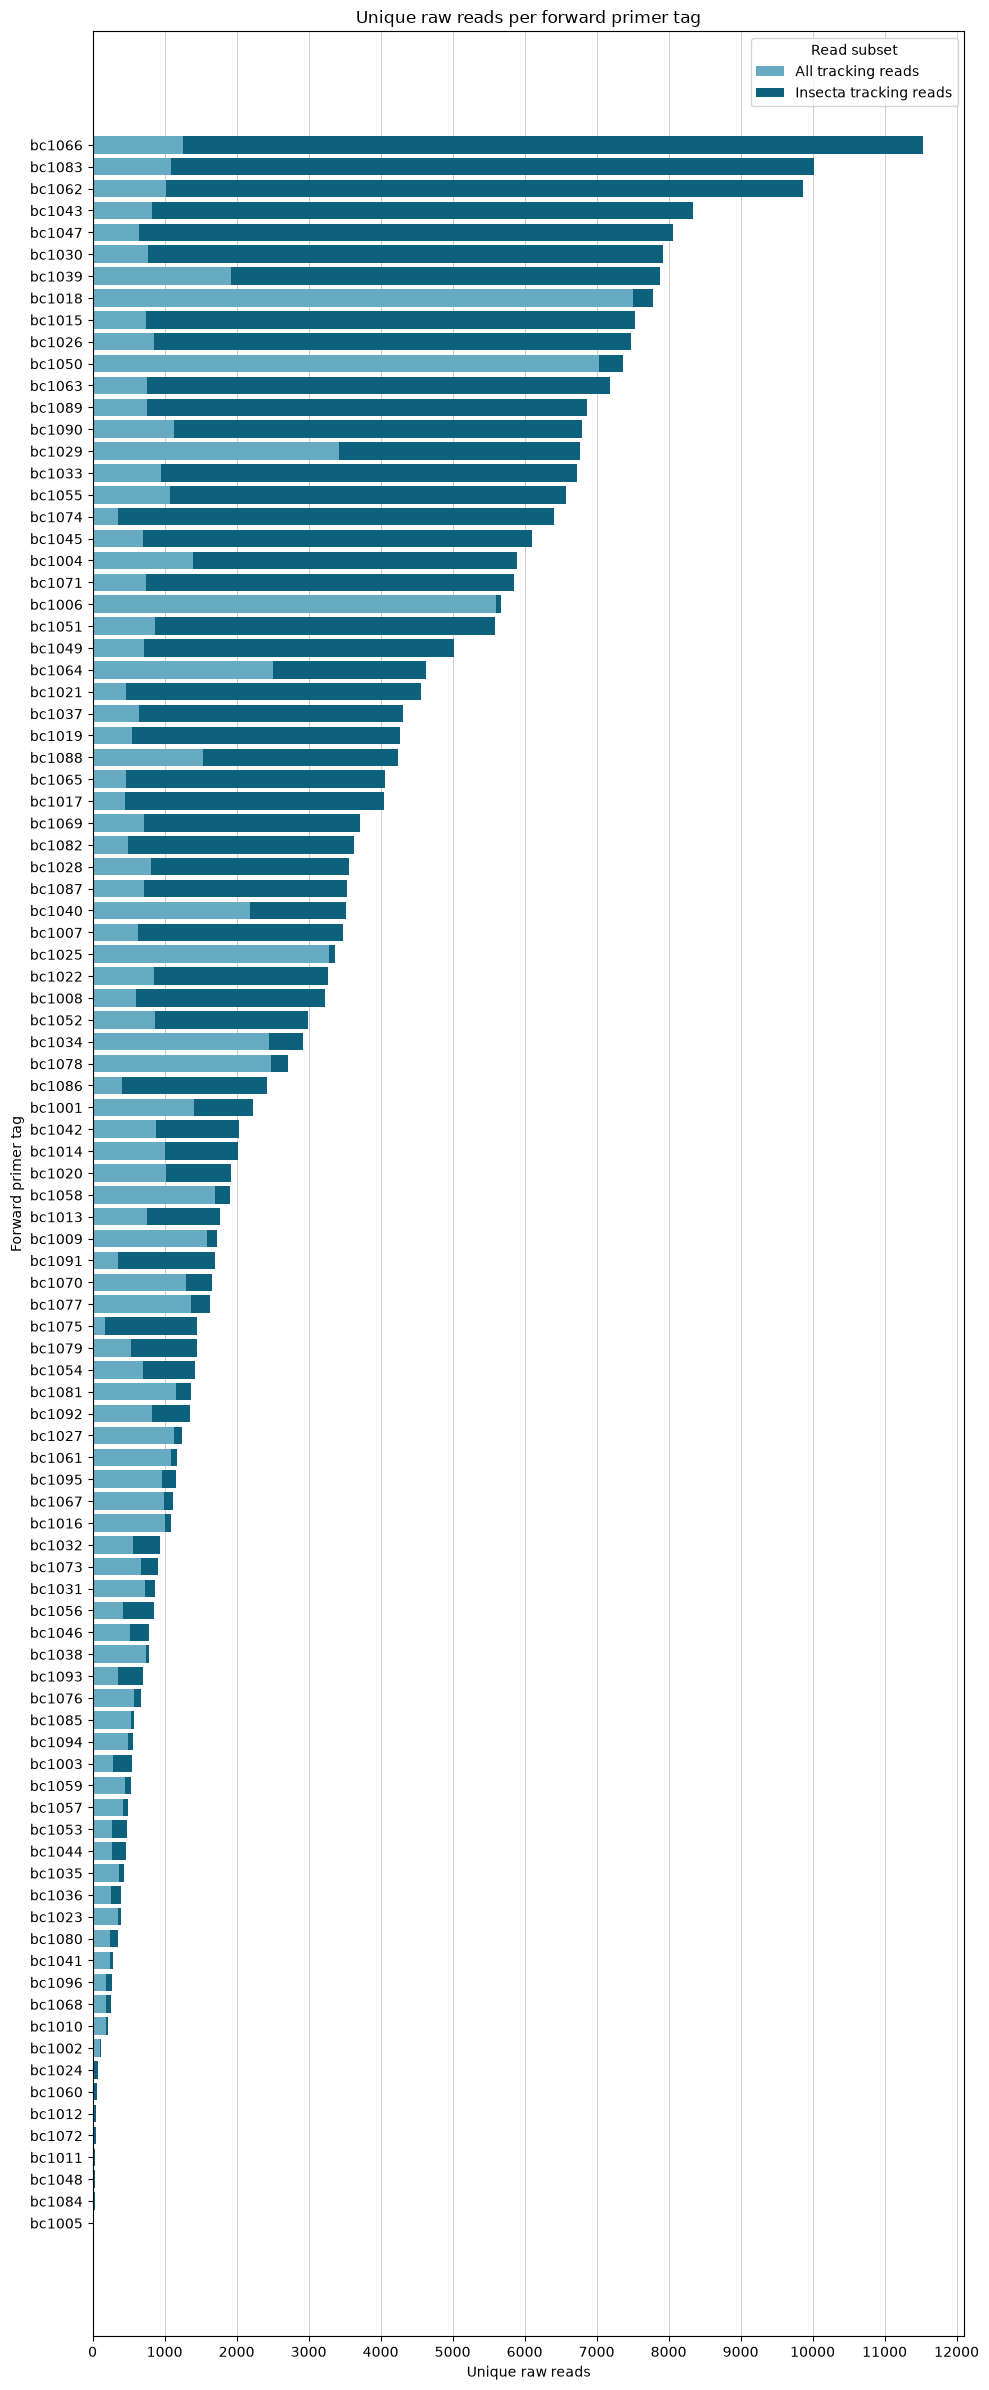

In [8]:
plot_data = reads_per_forward.sort_values('read_count',ascending=True,).copy()
# cuts everything lower than zero, not that it would happen
plot_data['read_count_non_insecta'] = (plot_data['read_count'] - plot_data['read_count_insecta']).clip(lower = 0)

fig, ax = plt.subplots(figsize=(10, max(6, 0.25 * len(plot_data))))
ax.set_axisbelow(True)
ax.xaxis.set_major_locator(MultipleLocator(1000))
ax.grid(axis='x', color='#bababa', linewidth=0.5)
ax.grid(axis='y', visible=False)

ax.barh(plot_data['forward_patternName'], plot_data['read_count_non_insecta'], color='#67abc2', 
        label='All tracking reads', zorder = 2)

ax.barh(plot_data['forward_patternName'], plot_data['read_count_insecta'], left = plot_data['read_count_non_insecta'],
    color='#0e617d', label='Insecta tracking reads', zorder = 2)

ax.set(title='Unique raw reads per forward primer tag', xlabel='Unique raw reads', ylabel='Forward primer tag')

ax.legend(title='Read subset')
plt.tight_layout()
fig.savefig(FIGURES_DIR / f'{SELECTED_BARCODE}_reads_per_forward_primer.png',
    dpi=250, bbox_inches='tight')
plt.show()

## Reads per reverse primer best hit

As with forward hits, `(reverse tag, raw read ID)` pairs are deduplicated so adapter-split fragments do not inflate counts.

,reverse_patternName,reverse_tag_number,read_count,read_count_insecta,read_count_non_insecta
0,bc1100rc,1100,2,1,1
1,bc1107rc,1107,278598,195758,82840
2,bc1122rc,1122,2894,1915,979


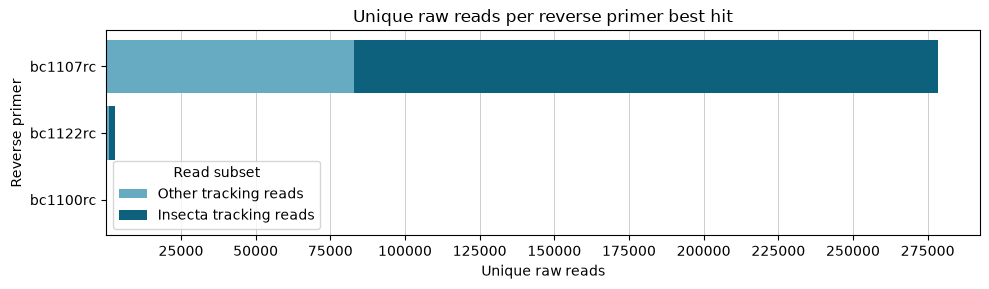

In [9]:
reverse_reads = (tracking.dropna(subset=['reverse_patternName'])
    [['reverse_patternName', 'reverse_tag_number', 'raw_ont_read_id']]
    .drop_duplicates(['reverse_patternName', 'raw_ont_read_id']).copy())

reverse_reads['is_insecta'] = reverse_reads['raw_ont_read_id'].isin(insecta_tracking['raw_ont_read_id'])

reads_per_reverse_tag = (reverse_reads
    .groupby(['reverse_patternName', 'reverse_tag_number'],as_index = False, dropna = False)
    .agg(read_count = ('raw_ont_read_id', 'nunique'), read_count_insecta = ('is_insecta', 'sum'))
    .sort_values(['reverse_tag_number', 'reverse_patternName']))

reads_per_reverse_tag['read_count_insecta'] = (reads_per_reverse_tag['read_count_insecta'].astype(int))

reads_per_reverse_tag['read_count_non_insecta'] = (reads_per_reverse_tag['read_count']
    - reads_per_reverse_tag['read_count_insecta'])

display(reads_per_reverse_tag)

plot_data = reads_per_reverse_tag.sort_values('read_count',ascending = True)

fig, ax = plt.subplots(figsize=(10, max(3, 0.4 * len(plot_data))))

ax.barh(plot_data['reverse_patternName'],plot_data['read_count_non_insecta'],
    color='#67abc2',label='Other tracking reads')

ax.barh(plot_data['reverse_patternName'],plot_data['read_count_insecta'],
    left=plot_data['read_count_non_insecta'],color='#0e617d',label='Insecta tracking reads')

ax.set(title='Unique raw reads per reverse primer best hit',xlabel='Unique raw reads',
    ylabel='Reverse primer')

ax.set_axisbelow(True)
ax.xaxis.set_major_locator(MultipleLocator(25000))
ax.grid(axis='x', color='#bababa', linewidth=0.5)
ax.grid(axis='y', visible=False)

ax.legend(title='Read subset')

plt.tight_layout()
fig.savefig(FIGURES_DIR / f'{SELECTED_BARCODE}_reads_per_reverse_primer.png',
    dpi=250, bbox_inches='tight')
plt.show()

## Unique taxids per forward primer tag

Distinct taxids are counted from distinct `(forward tag, taxid)` associations and uniquely from the insecta_tracking data, since we don't care (for now) about reads identified as anything else but insects. By default, taxid 0 is excluded because it means Kraken could not classify the sequence. Set `INCLUDE_UNCLASSIFIED_TAXID = True` in the configuration cell to include unclassified reads in calculations; since they are unclassified, it will be silly.

In [10]:
tag_taxid_pre = tracking.dropna(subset=['forward_patternName', 'taxid']).copy()
if not INCLUDE_UNCLASSIFIED_TAXID:
    tag_taxid_pre = tag_taxid_pre[tag_taxid_pre['taxid'] != 0]

unique_taxids_per_forward_all = (
    reads_per_forward[['forward_patternName', 'read_count']]
    .merge(
        tag_taxid_pre
        .groupby('forward_patternName', as_index=False)
        .agg(unique_taxid_count = ('taxid', 'nunique')),
        on='forward_patternName',
        how='left',
        validate='one_to_one'))

unique_taxids_per_forward_all['unique_taxid_count'] = (
    unique_taxids_per_forward_all['unique_taxid_count'].fillna(0).astype(int))

allreads_taxcount = dict(zip(unique_taxids_per_forward_all['forward_patternName'], unique_taxids_per_forward_all['unique_taxid_count']))
allreads_taxcount


{'bc1001': 114,
 'bc1002': 18,
 'bc1003': 28,
 'bc1004': 266,
 'bc1005': 4,
 'bc1006': 61,
 'bc1007': 114,
 'bc1008': 85,
 'bc1009': 64,
 'bc1010': 27,
 'bc1011': 8,
 'bc1012': 26,
 'bc1013': 56,
 'bc1014': 105,
 'bc1015': 246,
 'bc1016': 77,
 'bc1017': 127,
 'bc1018': 99,
 'bc1019': 153,
 'bc1020': 116,
 'bc1021': 170,
 'bc1022': 107,
 'bc1023': 24,
 'bc1024': 32,
 'bc1025': 136,
 'bc1026': 118,
 'bc1027': 52,
 'bc1028': 397,
 'bc1029': 219,
 'bc1030': 291,
 'bc1031': 52,
 'bc1032': 58,
 'bc1033': 169,
 'bc1034': 68,
 'bc1035': 48,
 'bc1036': 27,
 'bc1037': 83,
 'bc1038': 53,
 'bc1039': 274,
 'bc1040': 224,
 'bc1041': 26,
 'bc1042': 89,
 'bc1043': 606,
 'bc1044': 42,
 'bc1045': 109,
 'bc1046': 60,
 'bc1047': 175,
 'bc1048': 20,
 'bc1049': 465,
 'bc1050': 245,
 'bc1051': 138,
 'bc1052': 136,
 'bc1053': 24,
 'bc1054': 92,
 'bc1055': 299,
 'bc1056': 91,
 'bc1057': 42,
 'bc1058': 94,
 'bc1059': 42,
 'bc1060': 31,
 'bc1061': 66,
 'bc1062': 216,
 'bc1063': 144,
 'bc1064': 207,
 'bc1065': 16

In [11]:
tag_taxid = insecta_tracking.dropna(subset=['forward_patternName', 'taxid']).copy()
if not INCLUDE_UNCLASSIFIED_TAXID:
    tag_taxid = tag_taxid[tag_taxid['taxid'] != 0]

unique_taxids_per_forward_tag = (reads_per_forward[['forward_patternName', 'read_count_insecta']]
    .merge(
    tag_taxid.groupby('forward_patternName', as_index = False)
        .agg(unique_taxid_count=('taxid', 'nunique')),
    on = 'forward_patternName', how = 'left',
    validate = 'one_to_one'))

unique_taxids_per_forward_tag['unique_taxid_count'] = (unique_taxids_per_forward_tag['unique_taxid_count'].fillna(0).astype(int))

unique_taxids_per_forward_tag = unique_taxids_per_forward_tag.sort_values(by = 'forward_patternName')
unique_taxids_per_forward_tag['unique_taxid_noninsecta'] = (unique_taxids_per_forward_tag['forward_patternName'].map(allreads_taxcount)
                                                           - unique_taxids_per_forward_tag['unique_taxid_count'])

display(unique_taxids_per_forward_tag.sort_values(by = 'unique_taxid_count', ascending = False))

,forward_patternName,read_count_insecta,unique_taxid_count,unique_taxid_noninsecta
42,bc1043,7506,593,13
48,bc1049,4304,455,10
27,bc1028,2742,388,9
29,bc1030,7150,282,9
54,bc1055,5501,274,25
...,...,...,...,...
1,bc1002,25,15,3
71,bc1072,26,15,2
83,bc1084,24,12,2
10,bc1011,17,7,1


In [12]:
# sanity check
temp = tracking.dropna(subset=['forward_patternName', 'taxid']).copy()
if not INCLUDE_UNCLASSIFIED_TAXID:
    temp = temp[temp['taxid'] != 0]

temp = (temp.groupby('forward_patternName')['taxid'].nunique()
    .reset_index(name='unique_taxid_count')
    .sort_values(by='unique_taxid_count', ascending=False)
    .reset_index(drop=True))

print(temp)

   forward_patternName  unique_taxid_count
0               bc1043                 606
1               bc1049                 465
2               bc1028                 397
3               bc1055                 299
4               bc1030                 291
..                 ...                 ...
91              bc1002                  18
92              bc1072                  17
93              bc1084                  14
94              bc1011                   8
95              bc1005                   4

[96 rows x 2 columns]


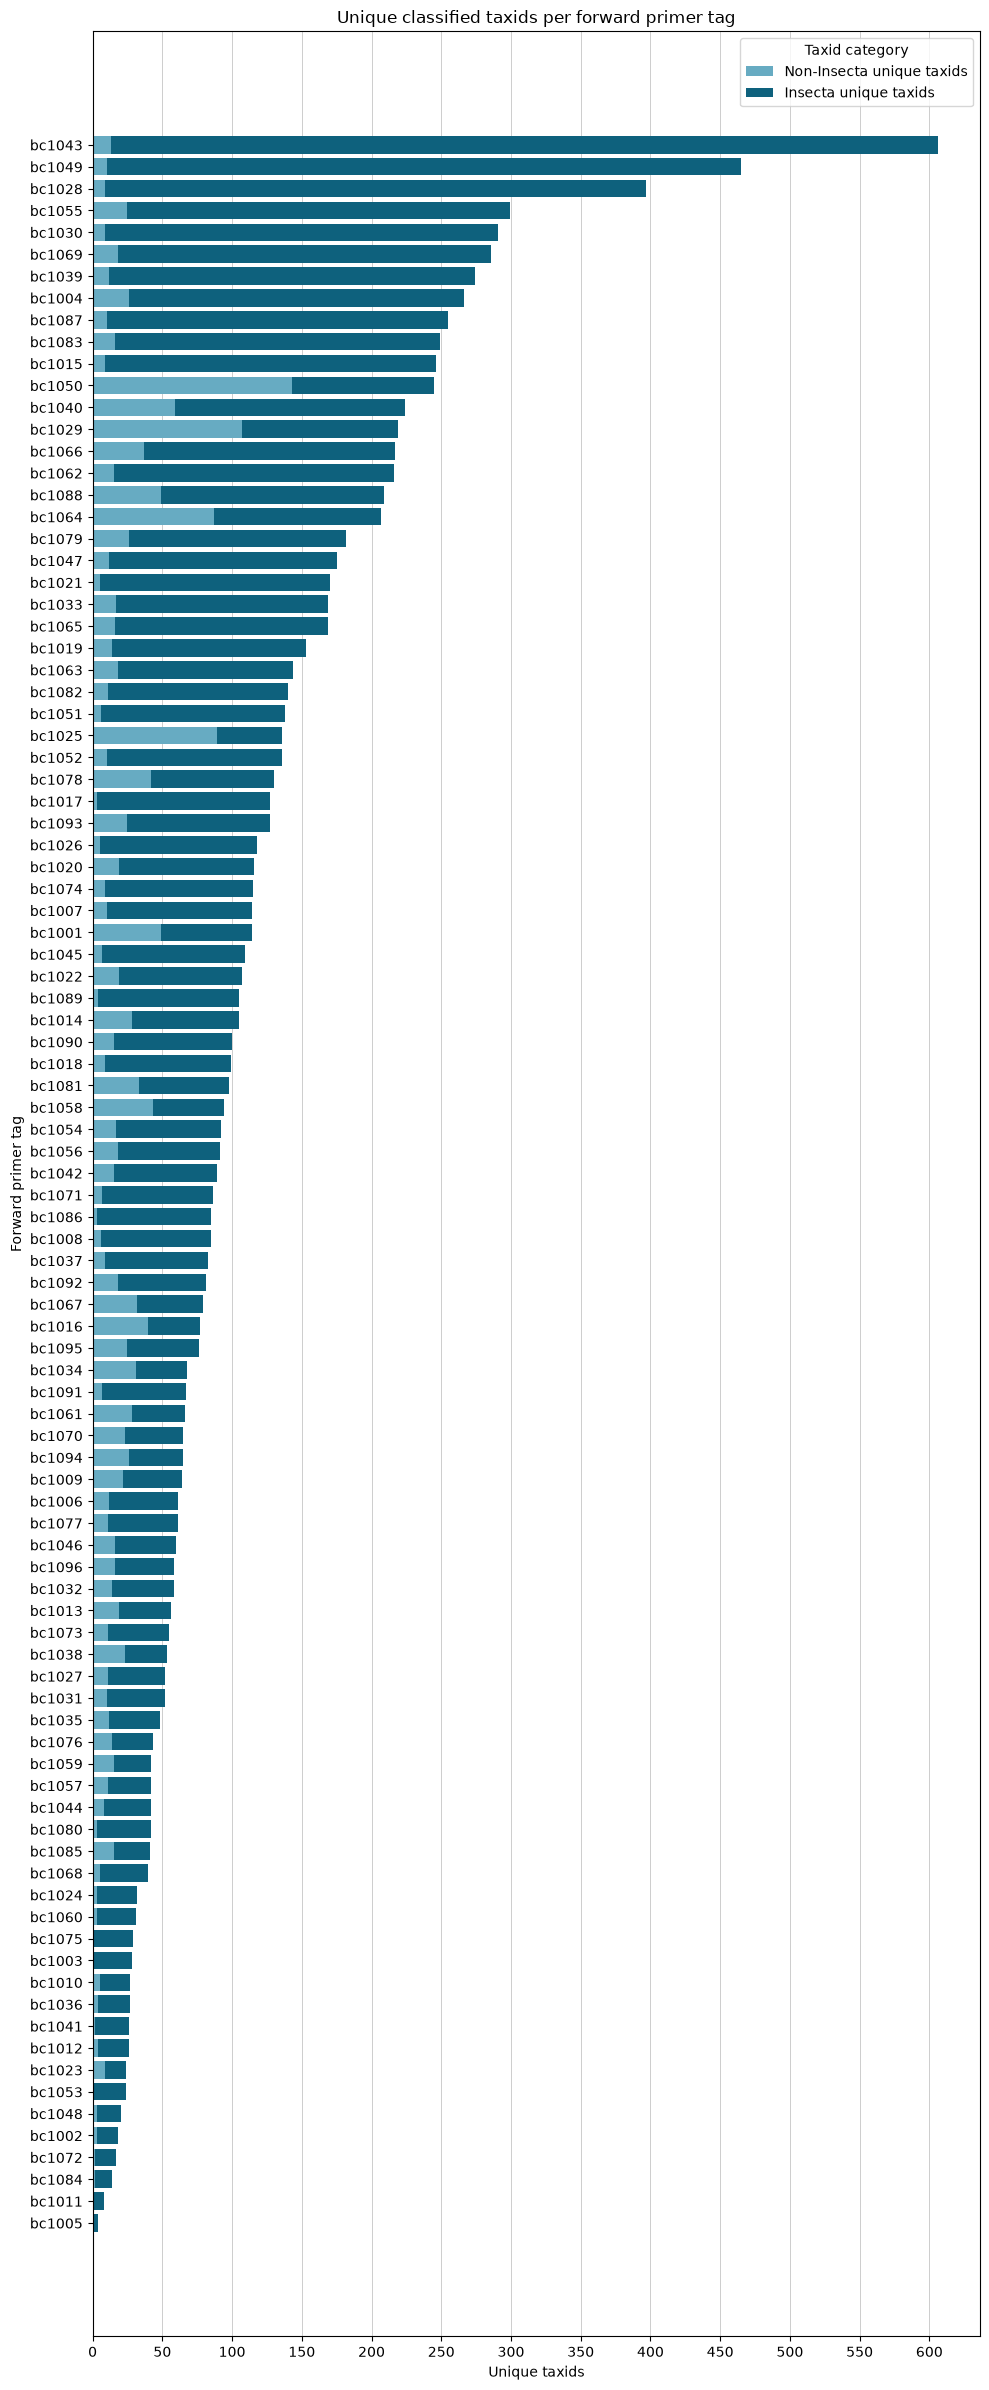

In [13]:
unique_taxids_per_forward_tag['total_read_count'] = (unique_taxids_per_forward_tag['unique_taxid_count']
        + unique_taxids_per_forward_tag['unique_taxid_noninsecta'])

plot_data = unique_taxids_per_forward_tag.sort_values(by = 'total_read_count', ascending=True).copy()

fig, ax = plt.subplots(figsize=(10, max(6, 0.25 * len(plot_data))))

ax.barh(plot_data['forward_patternName'],
    plot_data['unique_taxid_noninsecta'],
    color='#67abc2',
    label='Non-Insecta unique taxids')

ax.barh(plot_data['forward_patternName'],
    plot_data['unique_taxid_count'],
    left=plot_data['unique_taxid_noninsecta'],
    color='#0e617d',
    label='Insecta unique taxids')

ax.set(title='Unique classified taxids per forward primer tag',
    xlabel='Unique taxids',
    ylabel='Forward primer tag')

ax.set_axisbelow(True)
ax.xaxis.set_major_locator(MultipleLocator(50))
ax.grid(axis='x', color='#bababa', linewidth=0.5)
ax.grid(axis='y', visible=False)

ax.legend(title='Taxid category')

plt.tight_layout()
fig.savefig(FIGURES_DIR / f'{SELECTED_BARCODE}_unique_taxids_per_forward_primer.png',
    dpi=250, bbox_inches='tight')
plt.show()

## Read count versus taxid diversity

Each point is one forward primer and uses only `insecta_tracking`: distinct Insecta raw-read depth is on the x-axis and Insecta classified-taxid diversity is on the y-axis. Pearson's `r` measures their linear association; it does not establish causation.

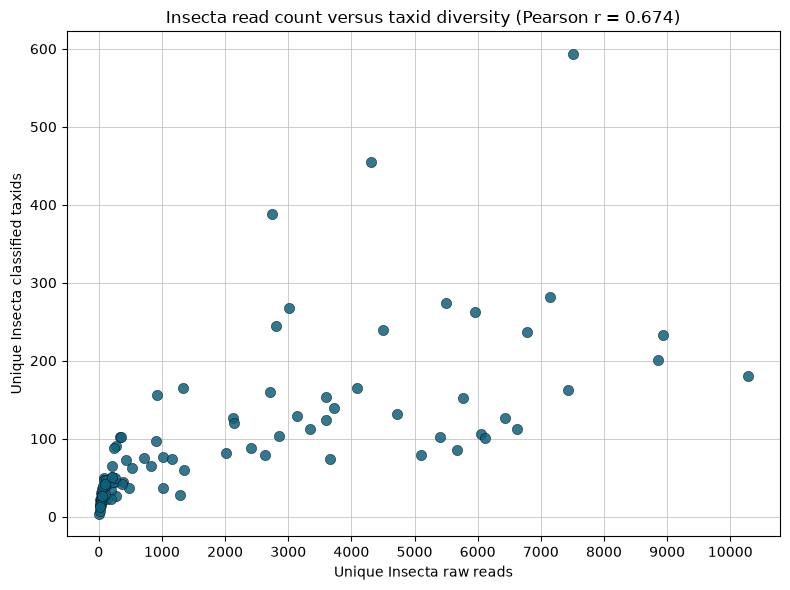

In [14]:
correlation = unique_taxids_per_forward_tag['read_count_insecta'].corr(
    unique_taxids_per_forward_tag['unique_taxid_count'])

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(unique_taxids_per_forward_tag['read_count_insecta'],
    unique_taxids_per_forward_tag['unique_taxid_count'],
    color='#0e617d', s=55, alpha=0.85, edgecolors='black', linewidths=0.35)

ax.set(title=f'Insecta read count versus taxid diversity (Pearson r = {correlation:.3f})',
    xlabel='Unique Insecta raw reads', ylabel='Unique Insecta classified taxids')

ax.set_axisbelow(True)
ax.xaxis.set_major_locator(MultipleLocator(1000))
ax.yaxis.set_major_locator(MultipleLocator(100))
ax.grid(axis='both', color='#bababa', linewidth=0.5)

plt.tight_layout()
fig.savefig(FIGURES_DIR / f'{SELECTED_BARCODE}_insecta_reads_vs_taxid_diversity.png',
    dpi=250, bbox_inches='tight')
plt.show()


## Ten most common taxids per forward primer

Taxid frequencies count distinct `(forward primer, taxid, raw read)` associations. Scientific names come from NCBI `names.dmp`, retaining only observed taxids. Taxa are ranked by descending unique-read count, with numeric taxid breaking ties. The output alternates `taxon_N` and `read_count_N`; missing ranks remain empty.

In [15]:
def read_scientific_names(names_dmp, wanted_taxids):
    taxid_to_name = {}
    with open(names_dmp, encoding='utf-8') as handle:
        for line in handle:
            fields = [field.strip() for field in line.split('|')]
            taxid = int(fields[0])
            if taxid in wanted_taxids and fields[3] == 'scientific name':
                taxid_to_name[taxid] = fields[1]
    return taxid_to_name

taxonomy_reads = insecta_tracking.dropna(subset=['taxid']).copy()
if not INCLUDE_UNCLASSIFIED_TAXID:
    taxonomy_reads = taxonomy_reads[taxonomy_reads['taxid'] != 0]
wanted_taxids = set(taxonomy_reads['taxid'].astype(int))
taxid_to_name = read_scientific_names(NAMES_DMP, wanted_taxids)

tag_taxid_read_counts = (
    tag_taxid[['forward_patternName', 'taxid', 'raw_ont_read_id']]
    .drop_duplicates(['forward_patternName', 'taxid', 'raw_ont_read_id'])
    .groupby(['forward_patternName', 'taxid'], as_index=False)
    .agg(read_count=('raw_ont_read_id', 'nunique'))
    .sort_values(
        ['forward_patternName', 'read_count', 'taxid'],
        ascending=[True, False, True]))

tag_taxid_read_counts['rank'] = (tag_taxid_read_counts.groupby('forward_patternName').cumcount() + 1)
tag_taxid_read_counts['scientific_name'] = (tag_taxid_read_counts['taxid'].map(taxid_to_name))

primer_order = reads_per_forward['forward_patternName'].tolist()
top10_long = tag_taxid_read_counts[tag_taxid_read_counts['rank'] <= 10]
top10_names = top10_long.pivot(
    index='forward_patternName', columns='rank', values='scientific_name'
).reindex(index=primer_order, columns=range(1, 11))
top10_counts = top10_long.pivot(
    index='forward_patternName', columns='rank', values='read_count'
).reindex(index=primer_order, columns=range(1, 11))

top10_taxa_per_forward_tag = pd.DataFrame(index=primer_order)
top10_taxa_per_forward_tag.index.name = 'forward_patternName'
for rank in range(1, 11):
    top10_taxa_per_forward_tag[f'taxon_{rank}'] = top10_names[rank]
    top10_taxa_per_forward_tag[f'read_count_{rank}'] = top10_counts[rank].astype('Int64')

top10_taxa_per_forward_tag = top10_taxa_per_forward_tag.reset_index()
display(top10_taxa_per_forward_tag)


,forward_patternName,taxon_1,read_count_1,taxon_2,read_count_2,taxon_3,read_count_3,taxon_4,read_count_4,taxon_5,...,taxon_6,read_count_6,taxon_7,read_count_7,taxon_8,read_count_8,taxon_9,read_count_9,taxon_10,read_count_10
0,bc1001,Pherbellia dubia,684,Acalyptratae,27,Eloeophila maculata,10,Musca autumnalis,9,Sciomyzidae,...,Pseudolycoriella brunnea,4,Diptera,3,Nematocera,3,Endopterygota,3,Muscoidea,3
1,bc1002,Cordyla fissa,5,Drosophila bifasciata,3,Schizophora,3,Clusiodes,2,Medetera sp. jka11-00407,...,Diptera,1,Chironomidae,1,Drosophilinae,1,Lasioglossum laevigatum,1,Sphaeroceridae,1
2,bc1003,Stegana,234,Stegana sp. BIOUG09995-G12,4,Lissonota,2,Bactrocera zonata,2,Drosophila tripunctata,...,Campopleginae sp. BOLD:ACF6578,2,Orthocladiinae sp. BOLD-2016,2,Diptera,1,Chironomidae,1,Endopterygota,1
3,bc1004,Muscoidea,3443,Calyptratae,238,Schizophora,60,Bassettia pallida,47,Schoenomyza litorella,...,Endopterygota,21,Sarcophaga ruficornis,20,Chrysomya rufifacies,19,Lucilia porphyrina,18,Bengalia peuhi,16
4,bc1005,Diptera,1,Endopterygota,1,Medetera sp. jka11-00407,1,Ectopsocidae sp.,1,NaN,...,NaN,<NA>,NaN,<NA>,NaN,<NA>,NaN,<NA>,NaN,<NA>
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
91,bc1092,Lordiphosa nigricolor,357,Eloeophila maculata,76,Nematocera,12,Diptera,4,unclassified Sciaridae,...,Ephydridae,3,Orthocladiinae sp. BOLD-2016,3,Aedes aegypti,2,Syrphidae,2,Eristalinae,2
92,bc1093,Brachycera,128,Rhypholophus varius,15,Diptera,13,Medetera sp. jka11-00407,12,Ditrysia,...,Chironominae environmental sample,10,Calyptratae,8,Formica,6,Nematocera,5,Endopterygota,5
93,bc1094,Sphaeroceridae,19,Orthocladiinae sp. BOLD-2016,4,Anaspis,3,Megaselia nigriceps,3,Psychoda cinerea,...,Ceratopogonidae,2,Schizopyga,2,Euplectus,2,Athetini,2,Bradysia trispinifera,2
94,bc1095,Gymnophora arcuata,91,Anisopodidae,21,Rhypholophus varius,16,Ditrysia,8,Fannia,...,Corynoptera deserta,4,Psychoda cinerea,3,Ichneumoninae sp. BBHYL725-10,3,Hilara canescens,3,Muscoidea,2


## Add sample ID and expected species

The join follows `SELECTED_BARCODE → PCR_plate/PCR_ID → Forward_tag_name → Sample_ID/sxdcode → species`. Join keys are normalized to lowercase, invisible edge characters are removed, whitespace and repeated underscores become one underscore, and leading/trailing underscores are removed. The code validates that the selected barcode has one PCR plate and each forward tag has one sample. If an `sxdcode` has multiple distinct species, all are retained in source order and separated with `;`. Positive and negative controls retain an empty species.

In [16]:
def normalize_join_value(value):
    if pd.isna(value):
        return pd.NA
    value = re.sub('[\u200b-\u200d\ufeff]', '', str(value))
    value = value.strip().lower()
    value = re.sub(r'[\s_]+', '_', value)
    return value.strip('_')

def normalized(series):
    return series.map(normalize_join_value).astype('string')

pool_map = pd.read_csv(POOL_MAP_FILE, sep='\t', dtype='string')
pcr_to_sample = pd.read_csv(PCR_TO_SAMPLE_FILE, sep='\t', dtype='string')
sample_to_species = pd.read_csv(SAMPLE_TO_SPECIES_FILE, sep='\t', dtype='string')

pool_map['barcode_key'] = normalized(pool_map['sequencing_barcode'])
pool_map['pcr_key'] = normalized(pool_map['PCR_plate'])
pcr_to_sample['pcr_key'] = normalized(pcr_to_sample['PCR_ID'])
pcr_to_sample['expected_forward'] = normalized(pcr_to_sample['Forward_tag_name'])
pcr_to_sample['expected_reverse'] = normalized(pcr_to_sample['Reverse_tag_name'])
pcr_to_sample['forward_tag_key'] = pcr_to_sample['expected_forward']
pcr_to_sample['reverse_primer'] = pcr_to_sample['expected_reverse']
pcr_to_sample['sample_id'] = normalized(pcr_to_sample['Sample_ID'])
sample_to_species['sample_id'] = normalized(sample_to_species['sxdcode'])
sample_to_species['species'] = normalized(sample_to_species['species'])

barcode_key = normalize_join_value(SELECTED_BARCODE)
pcr_matches = pool_map.loc[pool_map['barcode_key'] == barcode_key, 'pcr_key'].dropna().unique()
if len(pcr_matches) != 1:
    raise ValueError(f'{SELECTED_BARCODE!r} matched {len(pcr_matches)} PCR plates: {list(pcr_matches)}')
selected_pcr = pcr_matches[0]
selected_samples = pcr_to_sample[pcr_to_sample['pcr_key'] == selected_pcr].copy()

if selected_samples['forward_tag_key'].duplicated().any():
    duplicates = selected_samples.loc[
        selected_samples['forward_tag_key'].duplicated(keep=False), 'forward_tag_key'].tolist()
    print(f'Duplicate forward tags within {selected_pcr}; metadata will be collapsed: {duplicates}')

species_pairs = sample_to_species[['sample_id', 'species']].dropna(subset=['sample_id', 'species'])

def join_distinct_species(values):
    # dict preserves source order while removing repeated identical names.
    return ';'.join(dict.fromkeys(values))

def join_distinct_nonblank(values):
    cleaned = [value for value in values if pd.notna(value) and value]
    return ';'.join(dict.fromkeys(cleaned)) or pd.NA

species_lookup = (species_pairs.groupby('sample_id', as_index=False, sort=False)
    .agg(species=('species', join_distinct_species)))

primer_sample_rows = selected_samples[
    ['forward_tag_key', 'expected_forward', 'expected_reverse', 'reverse_primer', 'sample_id']
].merge(species_lookup, on='sample_id', how='left', validate='many_to_one')

primer_sample_lookup = (primer_sample_rows.groupby('forward_tag_key', as_index=False, sort=False)
    .agg(expected_forward=('expected_forward', join_distinct_nonblank),
        expected_reverse=('expected_reverse', join_distinct_nonblank),
        reverse_primer=('reverse_primer', join_distinct_nonblank),
        sample_id=('sample_id', join_distinct_nonblank),
        species=('species', join_distinct_nonblank)))

top10_taxa_per_forward_tag['forward_tag_key'] = normalized(
    top10_taxa_per_forward_tag['forward_patternName'])

top10_taxa_per_forward_tag = top10_taxa_per_forward_tag.merge(
    primer_sample_lookup,
    on='forward_tag_key',
    how='left',
    validate='one_to_one',
).drop(columns='forward_tag_key')

front_columns = ['forward_patternName', 'expected_forward', 'expected_reverse',
    'reverse_primer', 'sample_id', 'species']
top10_taxa_per_forward_tag = top10_taxa_per_forward_tag[
    front_columns + [column for column in top10_taxa_per_forward_tag.columns if column not in front_columns]]

print(f'{SELECTED_BARCODE} uses PCR plate {selected_pcr}')
print(f'Sample IDs matched: {top10_taxa_per_forward_tag.sample_id.notna().sum():,}')
print(f'Species matched: {top10_taxa_per_forward_tag.species.notna().sum():,}')
display(top10_taxa_per_forward_tag)
# top10_taxa_per_forward_tag[top10_taxa_per_forward_tag['species'].isna()]


barcode01 uses PCR plate pcrsxb_1_20260219
Sample IDs matched: 96
Species matched: 50


,forward_patternName,expected_forward,expected_reverse,reverse_primer,sample_id,species,taxon_1,read_count_1,taxon_2,read_count_2,...,taxon_6,read_count_6,taxon_7,read_count_7,taxon_8,read_count_8,taxon_9,read_count_9,taxon_10,read_count_10
0,bc1001,bc1001,bc1107rc,bc1107rc,sxb_75,<NA>,Pherbellia dubia,684,Acalyptratae,27,...,Pseudolycoriella brunnea,4,Diptera,3,Nematocera,3,Endopterygota,3,Muscoidea,3
1,bc1002,bc1002,bc1107rc,bc1107rc,sxb_55,paykullia_brevicornis,Cordyla fissa,5,Drosophila bifasciata,3,...,Diptera,1,Chironomidae,1,Drosophilinae,1,Lasioglossum laevigatum,1,Sphaeroceridae,1
2,bc1003,bc1003,bc1107rc,bc1107rc,sxb_85,<NA>,Stegana,234,Stegana sp. BIOUG09995-G12,4,...,Campopleginae sp. BOLD:ACF6578,2,Orthocladiinae sp. BOLD-2016,2,Diptera,1,Chironomidae,1,Endopterygota,1
3,bc1004,bc1004,bc1107rc,bc1107rc,sxb_45,mycophaga_testacea,Muscoidea,3443,Calyptratae,238,...,Endopterygota,21,Sarcophaga ruficornis,20,Chrysomya rufifacies,19,Lucilia porphyrina,18,Bengalia peuhi,16
4,bc1005,bc1005,bc1107rc,bc1107rc,sxb_38,<NA>,Diptera,1,Endopterygota,1,...,NaN,<NA>,NaN,<NA>,NaN,<NA>,NaN,<NA>,NaN,<NA>
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
91,bc1092,bc1092,bc1107rc,bc1107rc,sxb_76,<NA>,Lordiphosa nigricolor,357,Eloeophila maculata,76,...,Ephydridae,3,Orthocladiinae sp. BOLD-2016,3,Aedes aegypti,2,Syrphidae,2,Eristalinae,2
92,bc1093,bc1093,bc1107rc,bc1107rc,sxb_135,anthomyia_procellaris,Brachycera,128,Rhypholophus varius,15,...,Chironominae environmental sample,10,Calyptratae,8,Formica,6,Nematocera,5,Endopterygota,5
93,bc1094,bc1094,bc1107rc,bc1107rc,sxb_50,<NA>,Sphaeroceridae,19,Orthocladiinae sp. BOLD-2016,4,...,Ceratopogonidae,2,Schizopyga,2,Euplectus,2,Athetini,2,Bradysia trispinifera,2
94,bc1095,bc1095,bc1107rc,bc1107rc,sxb_113,<NA>,Gymnophora arcuata,91,Anisopodidae,21,...,Corynoptera deserta,4,Psychoda cinerea,3,Ichneumoninae sp. BBHYL725-10,3,Hilara canescens,3,Muscoidea,2


## Add genus and family for expected species and the top Kraken taxon

Expected genus is the leftmost word of each semicolon-separated expected species. NCBI `names.dmp` resolves expected species names to taxids, and `nodes.dmp` supplies parent lineages for expected family, the top-ranked Kraken taxon, and every taxid used for target detection. A taxon assigned above family receives neither genus nor family; a family assignment keeps family and leaves genus empty. `target_genus_detected` reports target genera found among all taxids for that forward primer, `target_detected_reverse` lists reverse primers on supporting reads, and `target_detected_readcount` counts distinct original ONT reads. All three remain empty when the target genus is not detected.

In [17]:
def expected_genera(species_value):
    if pd.isna(species_value):
        return pd.NA
    genera = [name.split('_', 1)[0] for name in species_value.split(';') if name]
    return ';'.join(dict.fromkeys(genera)) or pd.NA

def scientific_name_taxids(names_dmp, wanted_name_keys):
    matches = {name: [] for name in wanted_name_keys}
    with open(names_dmp, encoding='utf-8') as handle:
        for line in handle:
            fields = [field.strip() for field in line.split('|')]
            if fields[3] != 'scientific name':
                continue
            name_key = normalize_join_value(fields[1])
            if name_key in matches:
                matches[name_key].append(int(fields[0]))
    return matches

def lineage_subset(nodes_dmp, start_taxids):
    parent = {}
    rank = {}
    frontier = set(start_taxids)
    pass_number = 0
    stop_ranks = {'family', 'order', 'class', 'phylum', 'kingdom', 'superkingdom'}
    while frontier:
        pass_number += 1
        print(f'NCBI lineage pass {pass_number}: resolving {len(frontier):,} taxids ...')
        with open(nodes_dmp, encoding='utf-8') as handle:
            for line in handle:
                fields = [field.strip() for field in line.split('|')]
                taxid = int(fields[0])
                if taxid in frontier:
                    parent[taxid] = int(fields[1])
                    rank[taxid] = fields[2]
        next_frontier = {parent[taxid] for taxid in frontier
            if taxid in parent
            and parent[taxid] != taxid # not root
            and rank.get(taxid) not in stop_ranks # lower rank thank family
            and parent[taxid] not in rank} # not resloved yet in rank
        frontier = next_frontier
    print(f'NCBI lineage resolution completed in {pass_number} passes')
    return parent, rank
    
# annotate genus and family for species
def genus_family_taxids(taxid, parent, rank):
    genus_taxid = None
    family_taxid = None
    seen = set()
    current = int(taxid)
    while current not in seen and current in rank:
        seen.add(current)
        current_rank = rank[current]
        if current_rank == 'genus' and genus_taxid is None:
            genus_taxid = current
        if current_rank == 'family':
            family_taxid = current
            break
        if current_rank in {'order', 'class', 'phylum', 'kingdom', 'superkingdom'}:
            break
        next_taxid = parent.get(current)
        if next_taxid is None or next_taxid == current:
            break
        current = next_taxid
    return genus_taxid, family_taxid

top1_taxids = top10_long.loc[top10_long['rank'] == 1, ['forward_patternName', 'taxid']]
expected_species_keys = {name for value in top10_taxa_per_forward_tag['species'].dropna()
    for name in value.split(';') if name}
expected_genus_keys = {name.split('_', 1)[0] for name in expected_species_keys}
expected_name_keys = expected_species_keys | expected_genus_keys

# Include genera so family can still be resolved when an expected species
# has no exact scientific-name record in the NCBI taxonomy database.
expected_name_to_taxids = scientific_name_taxids(NAMES_DMP, expected_name_keys)

# Resolve every observed taxid because target detection uses all taxids, not only the top ten.
all_start_taxids = set(taxonomy_reads['taxid'].astype(int))
all_start_taxids.update(taxid for taxids in expected_name_to_taxids.values() for taxid in taxids)

taxid_to_parent_subset, taxid_to_rank_subset = lineage_subset(NODES_DMP, all_start_taxids)
lineage_ids = set()
lineage_by_taxid = {}
for taxid in all_start_taxids:
    genus_taxid, family_taxid = genus_family_taxids(
        taxid, taxid_to_parent_subset, taxid_to_rank_subset)
    lineage_by_taxid[taxid] = (genus_taxid, family_taxid)
    lineage_ids.update(value for value in [genus_taxid, family_taxid] if value is not None)
lineage_names = read_scientific_names(NAMES_DMP, lineage_ids)

# family of expected species, i.e. the species we think the specimen is
def expected_families(species_value):
    if pd.isna(species_value):
        return pd.NA
    families = []
    for species_key in species_value.split(';'):
        genus_key = species_key.split('_', 1)[0]
        # Prefer the exact species; fall back to its genus when NCBI does
        # not contain that species name.
        taxids = expected_name_to_taxids.get(species_key, [])
        if not taxids:
            taxids = expected_name_to_taxids.get(genus_key, [])
        for taxid in taxids:
            family_taxid = lineage_by_taxid.get(taxid, (None, None))[1]
            family = lineage_names.get(family_taxid)
            if family:
                families.append(family)
    return ';'.join(dict.fromkeys(families)) or pd.NA

top10_taxa_per_forward_tag['species_genus'] = (top10_taxa_per_forward_tag['species']
    .map(expected_genera).astype('string'))
top10_taxa_per_forward_tag['species_family'] = (top10_taxa_per_forward_tag['species']
    .map(expected_families).astype('string'))

top1_lineage = top1_taxids.copy()
# first get (checks dict without error if key doesn't exist) e.g. lineage_by_taxid = {2882605: (7370, 7367)}
# second get gets the species name (from the number)
# (None, None) is default returned if lineage not in dict for both elements of the dicts' value (Genus, Family)
top1_lineage['taxon_1_genus'] = top1_lineage['taxid'].map(
    lambda value: lineage_names.get(lineage_by_taxid.get(int(value), (None, None))[0]))
top1_lineage['taxon_1_family'] = top1_lineage['taxid'].map(
    lambda value: lineage_names.get(lineage_by_taxid.get(int(value), (None, None))[1]))

# get column name suffixes for when cell is ran multiple times without restarting the kernel
derived_prefixes = ('taxon_1_genus', 'taxon_1_family',
    'target_genus_detected', 'target_detected_reverse',
    'target_detected_readcount')

top10_taxa_per_forward_tag = top10_taxa_per_forward_tag.loc[:,
    ~top10_taxa_per_forward_tag.columns.str.startswith(derived_prefixes)].copy()

top10_taxa_per_forward_tag = top10_taxa_per_forward_tag.merge(
    top1_lineage[['forward_patternName', 'taxon_1_genus', 'taxon_1_family']],
    on='forward_patternName', how='left', validate='one_to_one')

# Compare the target genus with the NCBI genus of every taxid/read association.
target_genera_by_primer = {row.forward_patternName: set(row.species_genus.split(';'))
    for row in top10_taxa_per_forward_tag[['forward_patternName', 'species_genus']].itertuples(index=False)
    if pd.notna(row.species_genus)}

taxid_to_genus_name = {taxid: lineage_names.get(genus_taxid)
    for taxid, (genus_taxid, family_taxid) in lineage_by_taxid.items()}

target_detection_reads = tag_taxid[['forward_patternName', 'reverse_patternName', 'taxid', 'raw_ont_read_id']].copy()

target_detection_reads['taxid_genus'] = target_detection_reads['taxid'].map(taxid_to_genus_name)
target_detection_reads['taxid_genus_key'] = normalized(
    target_detection_reads['taxid_genus'])

target_detection_mask = [
    genus in target_genera_by_primer.get(primer, set())
    for primer, genus in zip(
        target_detection_reads['forward_patternName'],
        target_detection_reads['taxid_genus_key'])]
target_detection_reads = target_detection_reads.loc[target_detection_mask].drop_duplicates([
    'forward_patternName', 'reverse_patternName', 'taxid', 'raw_ont_read_id'])

def join_nonblank(values):
    if hasattr(values, 'dropna'):
        values = values.dropna()
    elif isinstance(values, str):
        values = [values]
    elif isinstance(values, (list, tuple, set)):
        values = list(values)
    elif pd.isna(values):
        return pd.NA
    else:
        values = [values]
    cleaned = [value for value in values if pd.notna(value) and value]
    return ';'.join(dict.fromkeys(cleaned)) or pd.NA

if target_detection_reads.empty:
    target_detection_summary = pd.DataFrame(columns=[
        'forward_patternName', 'target_genus_detected',
        'target_detected_reverse', 'target_detected_readcount'])
else:
    target_detection_summary = (target_detection_reads.groupby('forward_patternName', as_index=False)
        .agg(
            target_genus_detected=('taxid_genus_key', join_nonblank),
            target_detected_reverse=('reverse_patternName', join_nonblank),
            target_detected_readcount=('raw_ont_read_id', 'nunique')))

top10_taxa_per_forward_tag = top10_taxa_per_forward_tag.merge(
    target_detection_summary,
    on='forward_patternName',
    how='left',
    validate='one_to_one')

top10_taxa_per_forward_tag['target_detected_readcount'] = (top10_taxa_per_forward_tag['target_detected_readcount'].astype('Int64'))
ordered_front = [
    'forward_patternName', 'reverse_primer', 'sample_id', 'species', 'species_genus', 'species_family',
    'target_genus_detected', 'target_detected_reverse', 'target_detected_readcount',
    'taxon_1', 'taxon_1_genus', 'taxon_1_family', 'read_count_1']

top10_taxa_per_forward_tag = top10_taxa_per_forward_tag[
    ordered_front + [c for c in top10_taxa_per_forward_tag.columns if c not in ordered_front]]

display(top10_taxa_per_forward_tag)

NCBI lineage pass 1: resolving 5,681 taxids ...
NCBI lineage pass 2: resolving 2,757 taxids ...
NCBI lineage pass 3: resolving 1,167 taxids ...
NCBI lineage pass 4: resolving 244 taxids ...
NCBI lineage pass 5: resolving 21 taxids ...
NCBI lineage pass 6: resolving 3 taxids ...
NCBI lineage resolution completed in 6 passes


,forward_patternName,reverse_primer,sample_id,species,species_genus,species_family,target_genus_detected,target_detected_reverse,target_detected_readcount,taxon_1,...,taxon_6,read_count_6,taxon_7,read_count_7,taxon_8,read_count_8,taxon_9,read_count_9,taxon_10,read_count_10
0,bc1001,bc1107rc,sxb_75,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,Pherbellia dubia,...,Pseudolycoriella brunnea,4,Diptera,3,Nematocera,3,Endopterygota,3,Muscoidea,3
1,bc1002,bc1107rc,sxb_55,paykullia_brevicornis,paykullia,Rhinophoridae,<NA>,<NA>,<NA>,Cordyla fissa,...,Diptera,1,Chironomidae,1,Drosophilinae,1,Lasioglossum laevigatum,1,Sphaeroceridae,1
2,bc1003,bc1107rc,sxb_85,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,Stegana,...,Campopleginae sp. BOLD:ACF6578,2,Orthocladiinae sp. BOLD-2016,2,Diptera,1,Chironomidae,1,Endopterygota,1
3,bc1004,bc1107rc,sxb_45,mycophaga_testacea,mycophaga,Anthomyiidae,<NA>,<NA>,<NA>,Muscoidea,...,Endopterygota,21,Sarcophaga ruficornis,20,Chrysomya rufifacies,19,Lucilia porphyrina,18,Bengalia peuhi,16
4,bc1005,bc1107rc,sxb_38,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,Diptera,...,NaN,<NA>,NaN,<NA>,NaN,<NA>,NaN,<NA>,NaN,<NA>
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
91,bc1092,bc1107rc,sxb_76,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,Lordiphosa nigricolor,...,Ephydridae,3,Orthocladiinae sp. BOLD-2016,3,Aedes aegypti,2,Syrphidae,2,Eristalinae,2
92,bc1093,bc1107rc,sxb_135,anthomyia_procellaris,anthomyia,Anthomyiidae,<NA>,<NA>,<NA>,Brachycera,...,Chironominae environmental sample,10,Calyptratae,8,Formica,6,Nematocera,5,Endopterygota,5
93,bc1094,bc1107rc,sxb_50,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,Sphaeroceridae,...,Ceratopogonidae,2,Schizopyga,2,Euplectus,2,Athetini,2,Bradysia trispinifera,2
94,bc1095,bc1107rc,sxb_113,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,Gymnophora arcuata,...,Corynoptera deserta,4,Psychoda cinerea,3,Ichneumoninae sp. BBHYL725-10,3,Hilara canescens,3,Muscoidea,2


In [18]:
# checking that all species expected and detected have genus and family annotated
# the result of filtering shold be an empty dataframe
top10_taxa_per_forward_tag.columns
tempcols = ['species','species_genus', 'species_family', 'target_genus_detected',
       'target_detected_reverse', 'target_detected_readcount', 'taxon_1',
       'taxon_1_genus', 'taxon_1_family', 'read_count_1']
top10_taxa_per_forward_tag[~top10_taxa_per_forward_tag['species'].isna()
    & top10_taxa_per_forward_tag['species_family'].isna()][tempcols]

,species,species_genus,species_family,target_genus_detected,target_detected_reverse,target_detected_readcount,taxon_1,taxon_1_genus,taxon_1_family,read_count_1


## Insecta reads without a detected forward primer (`unsorted`)

This section runs after the NCBI lineage maps have been built. It uses only `insecta_tracking`, keeps classified reads without a forward-primer hit, resolves every taxid to its NCBI genus, and compares that genus with the expected target genera. It looks for our target species (genus) for the specimen amongst reads where we cannot find the primer tag (which can happen). Answers: Do we have our target sequences but we cannot detect them because these sequences don't have primer tags?

In [19]:
# Use only classified Insecta reads without a detected forward primer.
unsorted_reads = insecta_tracking[
    insecta_tracking['forward_patternName'].isna()
    & insecta_tracking['taxid'].notna()].copy()
if not INCLUDE_UNCLASSIFIED_TAXID:
    unsorted_reads = unsorted_reads[unsorted_reads['taxid'] != 0]
unsorted_reads['taxid'] = unsorted_reads['taxid'].astype(int)
unsorted_reads['taxon_name'] = unsorted_reads['taxid'].map(taxid_to_name)
unsorted_reads['taxid_genus'] = unsorted_reads['taxid'].map(taxid_to_genus_name)
unsorted_reads['taxid_genus_key'] = normalized(unsorted_reads['taxid_genus'])

# Build one target record per species. Semicolon-separated species remain
# aligned with the semicolon-separated genera derived above.
def split_semicolon_values(value):
    if pd.isna(value):
        return []
    return [item for item in str(value).split(';') if item]

target_records = []
target_source_columns = ['species', 'sample_id', 'forward_patternName', 'reverse_primer']

for species_cell, sample_id, forward_primer, reverse_primer in (
    top10_taxa_per_forward_tag[target_source_columns]
    .itertuples(index=False, name=None)):
    species_values = split_semicolon_values(species_cell)
    for species_value in species_values:
        genus_value = species_value.split('_', 1)[0]
        target_records.append({
            'taxid_genus_key': normalize_join_value(genus_value),
            'target_species': species_value,
            'target_sxdcode': sample_id,
            'target_forward_primers': forward_primer,
            'target_reverse_primers': reverse_primer})

target_record_columns = [
    'taxid_genus_key', 'target_species', 'target_sxdcode',
    'target_forward_primers', 'target_reverse_primers']
target_records = pd.DataFrame(target_records, columns=target_record_columns)
target_records = target_records[target_records['taxid_genus_key'].ne('')]

# Deduplicate species–sxdcode pairs together so both semicolon-separated
# this is because some taxonomists sent two or more specimen species data with the same saproxdna code (few, mistakes)
# columns retain exactly the same order and number of entries.
target_pairs = target_records.drop_duplicates(
    ['taxid_genus_key', 'target_species', 'target_sxdcode'])

target_pair_summary = (target_pairs
    .groupby('taxid_genus_key', as_index=False)
    .agg(
        target_species=('target_species', lambda values: ';'.join(values)),
        target_sxdcodes=('target_sxdcode', lambda values: ';'.join(values))))

target_primer_summary = (
    target_records.groupby('taxid_genus_key', as_index=False)
    .agg(
        target_forward_primers=('target_forward_primers', join_nonblank),
        target_reverse_primers=('target_reverse_primers', join_nonblank)))

target_by_genus = target_pair_summary.merge(
    target_primer_summary, on='taxid_genus_key', validate='one_to_one')

unsorted = (
    unsorted_reads
    .groupby(['taxid', 'taxon_name', 'taxid_genus', 'taxid_genus_key'], dropna=False, as_index=False)
    .agg(read_count=('raw_ont_read_id', 'nunique'))
    .merge(target_by_genus, on='taxid_genus_key', how='left', validate='many_to_one')
    .sort_values(['read_count', 'taxid'], ascending=[False, True]))

unsorted = unsorted[[
    'taxid', 'taxon_name', 'taxid_genus', 'read_count',
    'target_species', 'target_sxdcodes',
    'target_forward_primers', 'target_reverse_primers']]

print(f'Unsorted reads with a classified taxid: {unsorted_reads.raw_ont_read_id.nunique():,}')
print(f'Unique unsorted taxids: {len(unsorted):,}')
print(f'Taxids matching at least one target genus: {unsorted.target_species.notna().sum():,}')
display(unsorted)
# there might be more than 94 (minus poitive and negative controls) taxid's matching target genus;
# we are looking at target genus and not species first, because some specimens can be part of criptic species complexes
# or we simply cannot unambiguously identify specimens to the species level

Unsorted reads with a classified taxid: 113,816
Unique unsorted taxids: 4,345
Taxids matching at least one target genus: 126


,taxid,taxon_name,taxid_genus,read_count,target_species,target_sxdcodes,target_forward_primers,target_reverse_primers
4014,2882605,Phaonia mystica,Phaonia,6628,phaonia_villana;phaonia_villana;phaonia_pallid...,sxb_57;sxb_5;sxb_68;sxb_94;sxb_41;sxb_144;sxb_148,bc1026;bc1041;bc1050;bc1051;bc1077;bc1079;bc1090,bc1107rc
301,43754,Muscoidea,NaN,5386,NaN,NaN,NaN,NaN
65,7218,Drosophila bifasciata,Drosophila,4772,NaN,NaN,NaN,NaN
1322,500306,Clusiodes,Clusiodes,4604,clusiodes_apicalis,sxb_71,bc1037,bc1107rc
2966,1918234,Eloceria delecta,Eloceria,3272,eloceria_delecta;eloceria_delecta;eloceria_del...,sxb_54;sxb_112;sxb_149,bc1013;bc1060;bc1071,bc1107rc
...,...,...,...,...,...,...,...,...
4335,3403898,Tetreuaresta obscuriventris,Tetreuaresta,1,NaN,NaN,NaN,NaN
4336,3404708,Epochrinopsis sp. qu JS-2025a,Epochrinopsis,1,NaN,NaN,NaN,NaN
4339,3415878,Simulium kawamurae,Simulium,1,NaN,NaN,NaN,NaN
4342,3417491,Sarcophaga tsintaoensis,Sarcophaga,1,NaN,NaN,NaN,NaN


In [20]:
unsorted[~unsorted['target_species'].isna()][['taxon_name','read_count','target_species']]
print('Taxids read count congruent with target species and missing primer tags: ', 
      len(unsorted[~unsorted['target_species'].isna()]), ' out of %s taxids in unclassified reads\n'%(len(unsorted)))
for row in unsorted[~unsorted['target_species'].isna()][['taxon_name','read_count','target_species','target_forward_primers']].itertuples():
    print(row.taxon_name, 'Congruent taxid Found: ', row.target_species,'Forward primer: ',row.target_forward_primers,'\n')
unsorted.columns
# target species will have information if the read's taxid coincides to the genus level with the target species

Taxids read count congruent with target species and missing primer tags:  126  out of 4345 taxids in unclassified reads

Phaonia mystica Congruent taxid Found:  phaonia_villana;phaonia_villana;phaonia_pallida;phaonia_pallida;phaonia_palpata;phaonia_pallida;phaonia_canescens Forward primer:  bc1026;bc1041;bc1050;bc1051;bc1077;bc1079;bc1090 

Clusiodes Congruent taxid Found:  clusiodes_apicalis Forward primer:  bc1037 

Eloceria delecta Congruent taxid Found:  eloceria_delecta;eloceria_delecta;eloceria_delecta Forward primer:  bc1013;bc1060;bc1071 

Phaonia canescens Congruent taxid Found:  phaonia_villana;phaonia_villana;phaonia_pallida;phaonia_pallida;phaonia_palpata;phaonia_pallida;phaonia_canescens Forward primer:  bc1026;bc1041;bc1050;bc1051;bc1077;bc1079;bc1090 

Phaonia pallida Congruent taxid Found:  phaonia_villana;phaonia_villana;phaonia_pallida;phaonia_pallida;phaonia_palpata;phaonia_pallida;phaonia_canescens Forward primer:  bc1026;bc1041;bc1050;bc1051;bc1077;bc1079;bc1090 



Index(['taxid', 'taxon_name', 'taxid_genus', 'read_count', 'target_species',
       'target_sxdcodes', 'target_forward_primers', 'target_reverse_primers'],
      dtype='str')

In [21]:
# TODO ADD THE FORWARD PRIMER
# CHECK WHY Bibionidae s not annotated as a family for bibio_reticulatus
# why some families are not being annotated?
top10_taxa_per_forward_tag.columns
columns=['forward_patternName','sample_id', 'species',
       'species_genus', 'species_family','target_genus_detected',
       'target_detected_reverse', 'target_detected_readcount']
temp = top10_taxa_per_forward_tag[columns]
temp[~temp['species'].isna() & ~temp['target_genus_detected'].isna()]
top10_taxa_per_forward_tag.columns

Index(['forward_patternName', 'reverse_primer', 'sample_id', 'species',
       'species_genus', 'species_family', 'target_genus_detected',
       'target_detected_reverse', 'target_detected_readcount', 'taxon_1',
       'taxon_1_genus', 'taxon_1_family', 'read_count_1', 'expected_forward',
       'expected_reverse', 'taxon_2', 'read_count_2', 'taxon_3',
       'read_count_3', 'taxon_4', 'read_count_4', 'taxon_5', 'read_count_5',
       'taxon_6', 'read_count_6', 'taxon_7', 'read_count_7', 'taxon_8',
       'read_count_8', 'taxon_9', 'read_count_9', 'taxon_10', 'read_count_10'],
      dtype='str')

## Top-ten taxids stacked by forward primer

Each forward-primer bar contains its ten most frequent classified taxids plus one grey unclassified segment. Ten contrasting Matplotlib Tab10 categorical hues consistently represent taxon rank 1–10. A saturated segment means that taxid's NCBI genus matches an expected genus for that forward primer; a pale version means it does not. Counts follow the top-ten table and deduplicate `(forward primer, taxid, raw read)` associations.

A few bars show more than one expected genus matched by taxids. This happens because a taxonomist submitted more than one specimen identifications with different species and genus assigned to the sample saproxdna code (a few cases only).

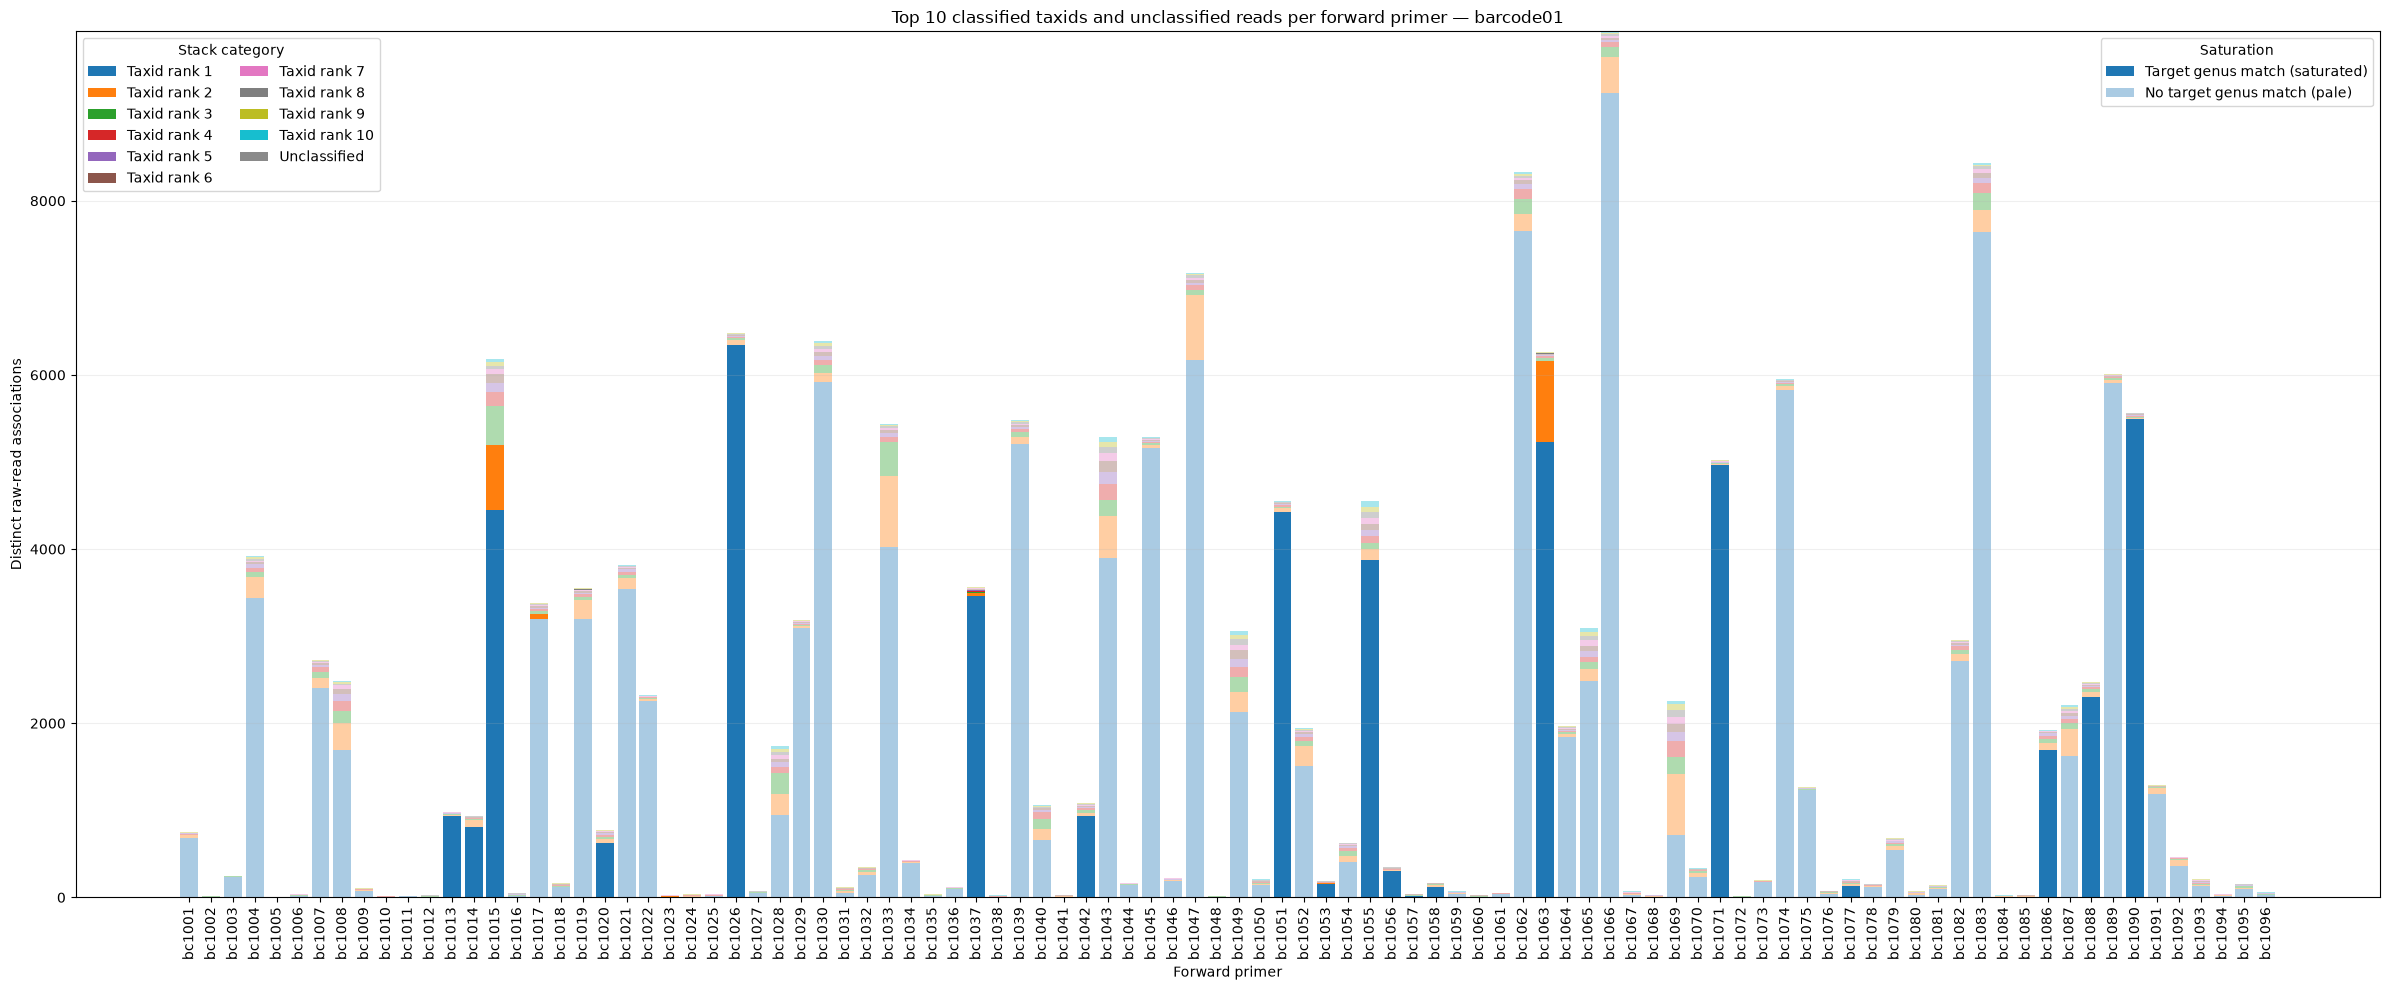

In [22]:
from matplotlib.patches import Patch

def desaturate_toward_white(color, white_fraction=0.62):
    rgb = color[:3]
    return tuple((1 - white_fraction) * channel + white_fraction for channel in rgb)

target_genera_by_primer = {
    row.forward_patternName: set(split_semicolon_values(row.species_genus))
    for row in top10_taxa_per_forward_tag[['forward_patternName', 'species_genus']].itertuples(index=False)}
stacked_taxa = top10_long.copy()
stacked_taxa['taxid_genus'] = stacked_taxa['taxid'].map(taxid_to_genus_name)
stacked_taxa['taxid_genus_key'] = normalized(stacked_taxa['taxid_genus'])
stacked_taxa['target_genus_match'] = stacked_taxa.apply(
    lambda row: row['taxid_genus_key'] in target_genera_by_primer.get(row['forward_patternName'], set()),
    axis=1)

unclassified_per_forward = (insecta_tracking[insecta_tracking['forward_patternName'].notna()
        & (insecta_tracking['taxid'].isna() | insecta_tracking['taxid'].eq(0))    ]
    .groupby('forward_patternName', as_index=False)
    .agg(unclassified_read_count=('raw_ont_read_id', 'nunique'))
    .set_index('forward_patternName')['unclassified_read_count'])

# The top-ten table is already in numeric PCR-primer order.
primer_order = top10_taxa_per_forward_tag['forward_patternName'].tolist()
rank_colors = {rank: plt.colormaps['tab10'](rank - 1) for rank in range(1, 11)}
bottom = pd.Series(0.0, index = primer_order)
fig, ax = plt.subplots(figsize = (24, 10))

for rank in range(1, 11):
    rank_rows = stacked_taxa[stacked_taxa['rank'] == rank].set_index('forward_patternName')
    heights = rank_rows['read_count'].reindex(primer_order).fillna(0)
    matches = rank_rows['target_genus_match'].reindex(primer_order).fillna(False)
    colors = [rank_colors[rank] if match else desaturate_toward_white(rank_colors[rank])
        for match in matches]
    ax.bar(primer_order, heights, bottom=bottom, color=colors, width=0.82)
    bottom = bottom.add(heights, fill_value=0)

unclassified_heights = unclassified_per_forward.reindex(primer_order).fillna(0)
ax.bar(primer_order, unclassified_heights, bottom=bottom,
    color='#8a8a8a', width=0.82)
ax.set(
    title=f'Top 10 classified taxids and unclassified reads per forward primer — {SELECTED_BARCODE}',
    xlabel='Forward primer',
    ylabel='Distinct raw-read associations')
ax.tick_params(axis='x', rotation=90)
ax.grid(axis='y', alpha=0.2)
ax.grid(axis='x', visible=False)
rank_legend = [Patch(facecolor = rank_colors[r], label = f'Taxid rank {r}') for r in range(1, 11)]
rank_legend.append(Patch(facecolor = '#8a8a8a', label = 'Unclassified'))
legend1 = ax.legend(handles=rank_legend, title = 'Stack category', ncol = 2, loc = 'upper left')
ax.add_artist(legend1)
match_legend = [
    Patch(facecolor=rank_colors[1], label = 'Target genus match (saturated)'),
    Patch(facecolor=desaturate_toward_white(rank_colors[1]), label = 'No target genus match (pale)')]
ax.legend(handles=match_legend, title='Saturation', loc='upper right')
plt.tight_layout()
fig.savefig(FIGURES_DIR / f'{SELECTED_BARCODE}_top10_taxids_per_forward_primer.png',
    dpi=250, bbox_inches='tight')
plt.show()


## Target-species detections across primer-identified and unidentified reads

A read supports a target species when the NCBI genus of its effective Insecta taxid equals the target species genus. Each row represents one target species, one detected taxid and one forward-primer status/identity. Multiple primers or taxids therefore create multiple rows while repeating the shared target metadata and summary counts. Counts use distinct original ONT read IDs. `taxid_detected_name` and `taxid_detected_genus` identify the detected NCBI taxon. `taxid_read_count` is the support for that taxid across primer statuses; `forward_primer_read_count` is target-genus support for that primer; `no_forward_primer_read_count` is target-genus support without a forward primer; and `target_species_read_count` is all target-genus support for that target species. After the 50% screen is calculated, `taxid_in_50pct_forward_primers` indicates whether each detected taxid belongs to that table.

In [23]:
target_species_records = []
for species_value in top10_taxa_per_forward_tag['species'].dropna():
    for target_species in split_semicolon_values(species_value):
        target_species_records.append({
            'target_species': target_species,
            'target_genus': target_species.split('_', 1)[0],
            'target_family': expected_families(target_species)})

target_species_metadata = (pd.DataFrame(target_species_records,
        columns=['target_species', 'target_genus', 'target_family'])
    .drop_duplicates(['target_species', 'target_genus', 'target_family']))
target_species_metadata['target_genus_key'] = normalized(target_species_metadata['target_genus'])

expected_species_context_records = []
for species_cell, sample_id, expected_forward, expected_reverse in (top10_taxa_per_forward_tag[
        ['species', 'sample_id', 'expected_forward', 'expected_reverse']]
        .itertuples(index=False, name=None)):
    for target_species in split_semicolon_values(species_cell):
        expected_species_context_records.append({
            'target_species': target_species,
            'target_sxdcode': sample_id,
            'expected_forward': expected_forward,
            'expected_reverse': expected_reverse})

expected_species_context = pd.DataFrame(expected_species_context_records,
    columns=['target_species', 'target_sxdcode', 'expected_forward', 'expected_reverse'])
expected_species_context = (expected_species_context.drop_duplicates()
    .groupby('target_species', as_index=False)
    .agg(target_sxdcodes=('target_sxdcode', join_nonblank),
        expected_forward=('expected_forward', join_nonblank),
        expected_reverse=('expected_reverse', join_nonblank)))

target_matches = (insecta_tracking
    .dropna(subset=['taxid'])
    .loc[lambda data: data['taxid'] != 0,
        ['raw_ont_read_id', 'forward_patternName', 'reverse_patternName', 'taxid']]
    .drop_duplicates(['raw_ont_read_id', 'forward_patternName', 'reverse_patternName', 'taxid'])
    .copy())
target_matches['taxid'] = target_matches['taxid'].astype(int)
target_matches['taxid_genus_key'] = normalized(target_matches['taxid'].map(taxid_to_genus_name))
target_matches['forward_primer_detected'] = target_matches['forward_patternName'].notna().map({True: 'yes', False: 'no'})
target_matches = target_matches.merge(target_species_metadata,
    left_on='taxid_genus_key', right_on='target_genus_key',
    how='inner', validate='many_to_many')

target_matches['taxid_read_count'] = (target_matches.groupby(
    ['target_species', 'taxid'])['raw_ont_read_id'].transform('nunique'))
target_matches['forward_primer_read_count'] = (target_matches.groupby(
    ['target_species', 'forward_patternName'], dropna=False)['raw_ont_read_id'].transform('nunique'))
target_matches.loc[target_matches['forward_primer_detected'] == 'no',
    'forward_primer_read_count'] = pd.NA
no_primer_counts = (target_matches[target_matches['forward_primer_detected'] == 'no']
    .groupby('target_species')['raw_ont_read_id'].nunique())
target_matches['no_forward_primer_read_count'] = (target_matches['target_species']
    .map(no_primer_counts).fillna(0).astype(int))
target_matches['target_species_read_count'] = (target_matches.groupby(
    'target_species')['raw_ont_read_id'].transform('nunique'))

target_species_detection_table = (target_matches.groupby([
        'target_species', 'target_genus', 'target_family',
        'forward_primer_detected', 'forward_patternName', 'taxid'],
        dropna=False, as_index=False)
    .agg(taxid_primer_read_count=('raw_ont_read_id', 'nunique'),
        taxid_read_count=('taxid_read_count', 'max'),
        forward_primer_read_count=('forward_primer_read_count', 'max'),
        detected_reverse_primers=('reverse_patternName', join_nonblank),
        no_forward_primer_read_count=('no_forward_primer_read_count', 'max'),
        target_species_read_count=('target_species_read_count', 'max'))
    .rename(columns={'forward_patternName': 'forward_primer',
        'taxid': 'taxid_detected'}))
target_species_detection_table['forward_primer_read_count'] = (
    target_species_detection_table['forward_primer_read_count'].astype('Int64'))
target_species_detection_table = (target_species_metadata.drop(columns='target_genus_key')
    .merge(target_species_detection_table,
        on=['target_species', 'target_genus', 'target_family'],
        how='left', validate='one_to_many')
    .sort_values(['target_species', 'forward_primer_detected',
        'forward_primer', 'taxid_detected'], na_position='last')
    .reset_index(drop=True))
target_species_detection_table['taxid_detected_name'] = (
    target_species_detection_table['taxid_detected'].map(taxid_to_name).astype('string'))
target_species_detection_table['taxid_detected_genus'] = (
    target_species_detection_table['taxid_detected'].map(taxid_to_genus_name).astype('string'))

target_species_detection_table = target_species_detection_table.merge(
    expected_species_context, on='target_species', how='left', validate='many_to_one')

def semicolon_set(value):
    if pd.isna(value):
        return set()
    return {item for item in str(value).split(';') if item}

def has_semicolon_overlap(left, right):
    left_values = semicolon_set(left)
    right_values = semicolon_set(right)
    return bool(left_values and right_values and left_values.intersection(right_values))

target_species_detection_table['forward_primer_agrees_expected'] = pd.NA
has_detected_forward = target_species_detection_table['forward_primer'].notna()
target_species_detection_table.loc[has_detected_forward,
    'forward_primer_agrees_expected'] = (target_species_detection_table.loc[has_detected_forward]
        .apply(lambda row: has_semicolon_overlap(row['forward_primer'], row['expected_forward']), axis=1)
        .map({True: 'yes', False: 'no'}))

target_species_detection_table['reverse_primer_agrees_expected'] = pd.NA
has_detected_reverse = target_species_detection_table['detected_reverse_primers'].notna()
target_species_detection_table.loc[has_detected_reverse,
    'reverse_primer_agrees_expected'] = (target_species_detection_table.loc[has_detected_reverse]
        .apply(lambda row: has_semicolon_overlap(row['detected_reverse_primers'], row['expected_reverse']), axis=1)
        .map({True: 'yes', False: 'no'}))

ordered_front = [
    'target_species', 'target_genus', 'target_family', 'target_sxdcodes',
    'expected_forward', 'expected_reverse', 'forward_primer_detected',
    'forward_primer', 'forward_primer_agrees_expected',
    'detected_reverse_primers', 'reverse_primer_agrees_expected']
target_species_detection_table = target_species_detection_table[
    ordered_front + [column for column in target_species_detection_table.columns
        if column not in ordered_front]]


## Taxids detected across at least 50% of forward primers

This screen uses classified `insecta_tracking` reads with a detected forward primer. The denominator is the number of distinct forward primers observed in that table. Taxids retained at the 50% threshold include scientific name/genus, detected and missing primer lists, distinct supporting raw-read counts, and evidence from classified Insecta reads without a forward-primer detection.

In [24]:
forward_primer_order = (insecta_tracking
    .dropna(subset=['forward_patternName'])
    [['forward_patternName', 'forward_tag_number']]
    .drop_duplicates()
    .sort_values(['forward_tag_number', 'forward_patternName'])
    ['forward_patternName'].tolist())

forward_taxid_reads = (insecta_tracking
    .dropna(subset=['forward_patternName', 'taxid'])
    .loc[lambda data: data['taxid'] != 0,
        ['raw_ont_read_id', 'forward_patternName', 'reverse_patternName', 'taxid']]
    .drop_duplicates(['raw_ont_read_id', 'forward_patternName', 'reverse_patternName', 'taxid'])
    .copy())
forward_taxid_reads['taxid'] = forward_taxid_reads['taxid'].astype(int)
taxid_forward_summary = (forward_taxid_reads.groupby('taxid', as_index=False)
    .agg(forward_primer_count=('forward_patternName', 'nunique'),
        forward_primer_detected=('forward_patternName',
            lambda values: ';'.join(primer for primer in forward_primer_order
                if primer in set(values))),
        detected_reverse_primers=('reverse_patternName', join_nonblank),
        forward_primer_read_count=('raw_ont_read_id', 'nunique')))
taxid_forward_summary['forward_primer_percentage'] = (100 *
    taxid_forward_summary['forward_primer_count'] / len(forward_primer_order)).round(2)
taxid_forward_summary['forward_primer_not_detected'] = (
    taxid_forward_summary['forward_primer_detected'].map(
        lambda detected: ';'.join(primer for primer in forward_primer_order
            if primer not in set(detected.split(';')))))

expected_forward_by_detected_forward = dict(zip(
    primer_sample_lookup['expected_forward'], primer_sample_lookup['expected_forward']))
expected_reverse_by_detected_forward = dict(zip(
    primer_sample_lookup['expected_forward'], primer_sample_lookup['expected_reverse']))

def expected_values_for_detected_forwards(detected_forwards, lookup):
    values = []
    for primer in semicolon_set(detected_forwards):
        value = lookup.get(primer)
        if pd.notna(value):
            values.append(value)
    return join_nonblank(values)

taxid_forward_summary['expected_forward'] = taxid_forward_summary['forward_primer_detected'].map(
    lambda value: expected_values_for_detected_forwards(value, expected_forward_by_detected_forward))
taxid_forward_summary['expected_reverse'] = taxid_forward_summary['forward_primer_detected'].map(
    lambda value: expected_values_for_detected_forwards(value, expected_reverse_by_detected_forward))
taxid_forward_summary['forward_primer_agrees_expected'] = taxid_forward_summary.apply(
    lambda row: has_semicolon_overlap(row['forward_primer_detected'], row['expected_forward']), axis=1)
taxid_forward_summary['forward_primer_agrees_expected'] = (
    taxid_forward_summary['forward_primer_agrees_expected'].map({True: 'yes', False: 'no'}))
taxid_forward_summary['reverse_primer_agrees_expected'] = taxid_forward_summary.apply(
    lambda row: has_semicolon_overlap(row['detected_reverse_primers'], row['expected_reverse']), axis=1)
taxid_forward_summary['reverse_primer_agrees_expected'] = (
    taxid_forward_summary['reverse_primer_agrees_expected'].map({True: 'yes', False: 'no'}))

no_forward_taxid_counts = (insecta_tracking[
        insecta_tracking['forward_patternName'].isna()
        & insecta_tracking['taxid'].notna()
        & insecta_tracking['taxid'].ne(0)]
    .groupby('taxid')['raw_ont_read_id'].nunique())
taxid_forward_summary['no_forward_primer_read_count'] = (
    taxid_forward_summary['taxid'].map(no_forward_taxid_counts).fillna(0).astype(int))
taxid_forward_summary['detected_without_forward_primer'] = (
    taxid_forward_summary['no_forward_primer_read_count'].gt(0).map({True: 'yes', False: 'no'}))
taxid_forward_summary['taxid_name'] = taxid_forward_summary['taxid'].map(taxid_to_name)
taxid_forward_summary['taxid_genus'] = taxid_forward_summary['taxid'].map(taxid_to_genus_name)

widespread_taxids = (taxid_forward_summary[
        taxid_forward_summary['forward_primer_percentage'] >= 50]
    [['taxid', 'taxid_name', 'taxid_genus', 'forward_primer_count',
        'forward_primer_percentage', 'forward_primer_detected',
        'forward_primer_not_detected', 'expected_forward', 'expected_reverse',
        'forward_primer_agrees_expected', 'detected_reverse_primers',
        'reverse_primer_agrees_expected', 'forward_primer_read_count',
        'detected_without_forward_primer', 'no_forward_primer_read_count']]
    .sort_values(['forward_primer_percentage', 'forward_primer_read_count'],
        ascending=[False, False]).reset_index(drop=True))

target_species_detection_table['taxid_in_50pct_forward_primers'] = pd.NA
detected_taxid_rows = target_species_detection_table['taxid_detected'].notna()
target_species_detection_table.loc[detected_taxid_rows,
    'taxid_in_50pct_forward_primers'] = (target_species_detection_table.loc[
        detected_taxid_rows, 'taxid_detected'].astype(int)
        .isin(set(widespread_taxids['taxid'])).map({True: 'yes', False: 'no'}))
target_species_detection_table['taxid_in_50pct_forward_primers'] = (
    target_species_detection_table['taxid_in_50pct_forward_primers'].astype('string'))

display(widespread_taxids)
display(target_species_detection_table)


AttributeError: 'list' object has no attribute 'dropna'

## Target-species taxids below the 50% forward-primer threshold

This is a direct filter of `target_species_detection_table`. It retains rows with a detected taxid where `taxid_in_50pct_forward_primers` is `no`. Rows with and without a detected forward primer are both retained, as are repeated target-species details needed to preserve each primer/taxid association.

In [ ]:
target_species_taxids_below_50pct = (target_species_detection_table[
        target_species_detection_table['taxid_detected'].notna()
        & target_species_detection_table['taxid_in_50pct_forward_primers'].eq('no')]
    .copy().reset_index(drop=True))
display(target_species_taxids_below_50pct)


## Expected species not detected

This table starts from the expected target-species metadata and keeps species for which no classified Insecta taxid matched the expected target genus. The expected sxdcode and primer columns are added only as context for tracing the missing target back to the PCR/sample metadata.

In [ ]:
detected_target_species = set(target_species_detection_table.loc[
    target_species_detection_table['taxid_detected'].notna(), 'target_species'])

expected_species_not_detected = (target_species_metadata.drop(columns='target_genus_key')
    .merge(expected_species_context, on='target_species', how='left', validate='one_to_one')
    .loc[lambda data: ~data['target_species'].isin(detected_target_species)]
    .sort_values(['target_species'])
    .reset_index(drop=True))

display(expected_species_not_detected)


## Export analysis tables

Exports use the selected sequencing barcode in their filenames and are written beside the reduced tracking input. Missing values are exported as empty TSV cells.

In [ ]:
TOP10_OUTPUT = INPUT_FILE.parent / f'{SELECTED_BARCODE}_top10_taxa_per_forward_tag.tsv'
UNSORTED_OUTPUT = INPUT_FILE.parent / f'{SELECTED_BARCODE}_unsorted_taxa.tsv'
SUMMARY_OUTPUT = INPUT_FILE.parent / f'{SELECTED_BARCODE}_primer_detection_classification_summary.tsv'
TARGET_SPECIES_OUTPUT = INPUT_FILE.parent / f'{SELECTED_BARCODE}_target_species_detection.tsv'
WIDESPREAD_TAXIDS_OUTPUT = INPUT_FILE.parent / f'{SELECTED_BARCODE}_taxids_across_50pct_forward_primers.tsv'
TARGET_SPECIES_BELOW_50PCT_OUTPUT = INPUT_FILE.parent / f'{SELECTED_BARCODE}_target_species_taxids_below_50pct_forward_primers.tsv'
EXPECTED_SPECIES_NOT_DETECTED_OUTPUT = INPUT_FILE.parent / f'{SELECTED_BARCODE}_expected_species_not_detected.tsv'

top10_taxa_per_forward_tag.to_csv(TOP10_OUTPUT, sep='\t', index=False, na_rep='')
unsorted.to_csv(UNSORTED_OUTPUT, sep='\t', index=False, na_rep='')
primer_detection_summary.to_csv(
    SUMMARY_OUTPUT, sep='\t', index=False, na_rep=''
)
target_species_detection_table.to_csv(
    TARGET_SPECIES_OUTPUT, sep='\t', index=False, na_rep='')
widespread_taxids.to_csv(
    WIDESPREAD_TAXIDS_OUTPUT, sep='\t', index=False, na_rep='')
target_species_taxids_below_50pct.to_csv(
    TARGET_SPECIES_BELOW_50PCT_OUTPUT, sep='\t', index=False, na_rep='')
expected_species_not_detected.to_csv(
    EXPECTED_SPECIES_NOT_DETECTED_OUTPUT, sep='\t', index=False, na_rep='')

print(f'Exported {len(top10_taxa_per_forward_tag):,} rows to {TOP10_OUTPUT}')
# print(f'Exported {len(unsorted):,} rows to {UNSORTED_OUTPUT}')
# print(f'Exported {len(primer_detection_summary):,} rows to {SUMMARY_OUTPUT}')
print(f'Exported {len(target_species_detection_table):,} rows to {TARGET_SPECIES_OUTPUT}')
print(f'Exported {len(widespread_taxids):,} rows to {WIDESPREAD_TAXIDS_OUTPUT}')
print(f'Exported {len(target_species_taxids_below_50pct):,} rows to {TARGET_SPECIES_BELOW_50PCT_OUTPUT}')
print(f'Exported {len(expected_species_not_detected):,} rows to {EXPECTED_SPECIES_NOT_DETECTED_OUTPUT}')
